## 📐 Radius of Gyration (Rg) — cMD

Plots Rg time traces for all canonical MD systems:

- **6ONI**: apo, pep-nolig, ligand, pep-lig  
- **6ONJ**: apo, pep-nolig, ligand, pep-lig  
- **3PRG**: apo

Each panel shows:
- Individual replicas (**rep1–rep3**)
- Smoothed mean trace (rolling window = 160 frames)

**Input:** `cMD/<system>/repX/Rg.dat`  
**Time unit:** ns (frames ÷ 100)  
**Output:** `Plots/cMD/Rg_cMD.svg`


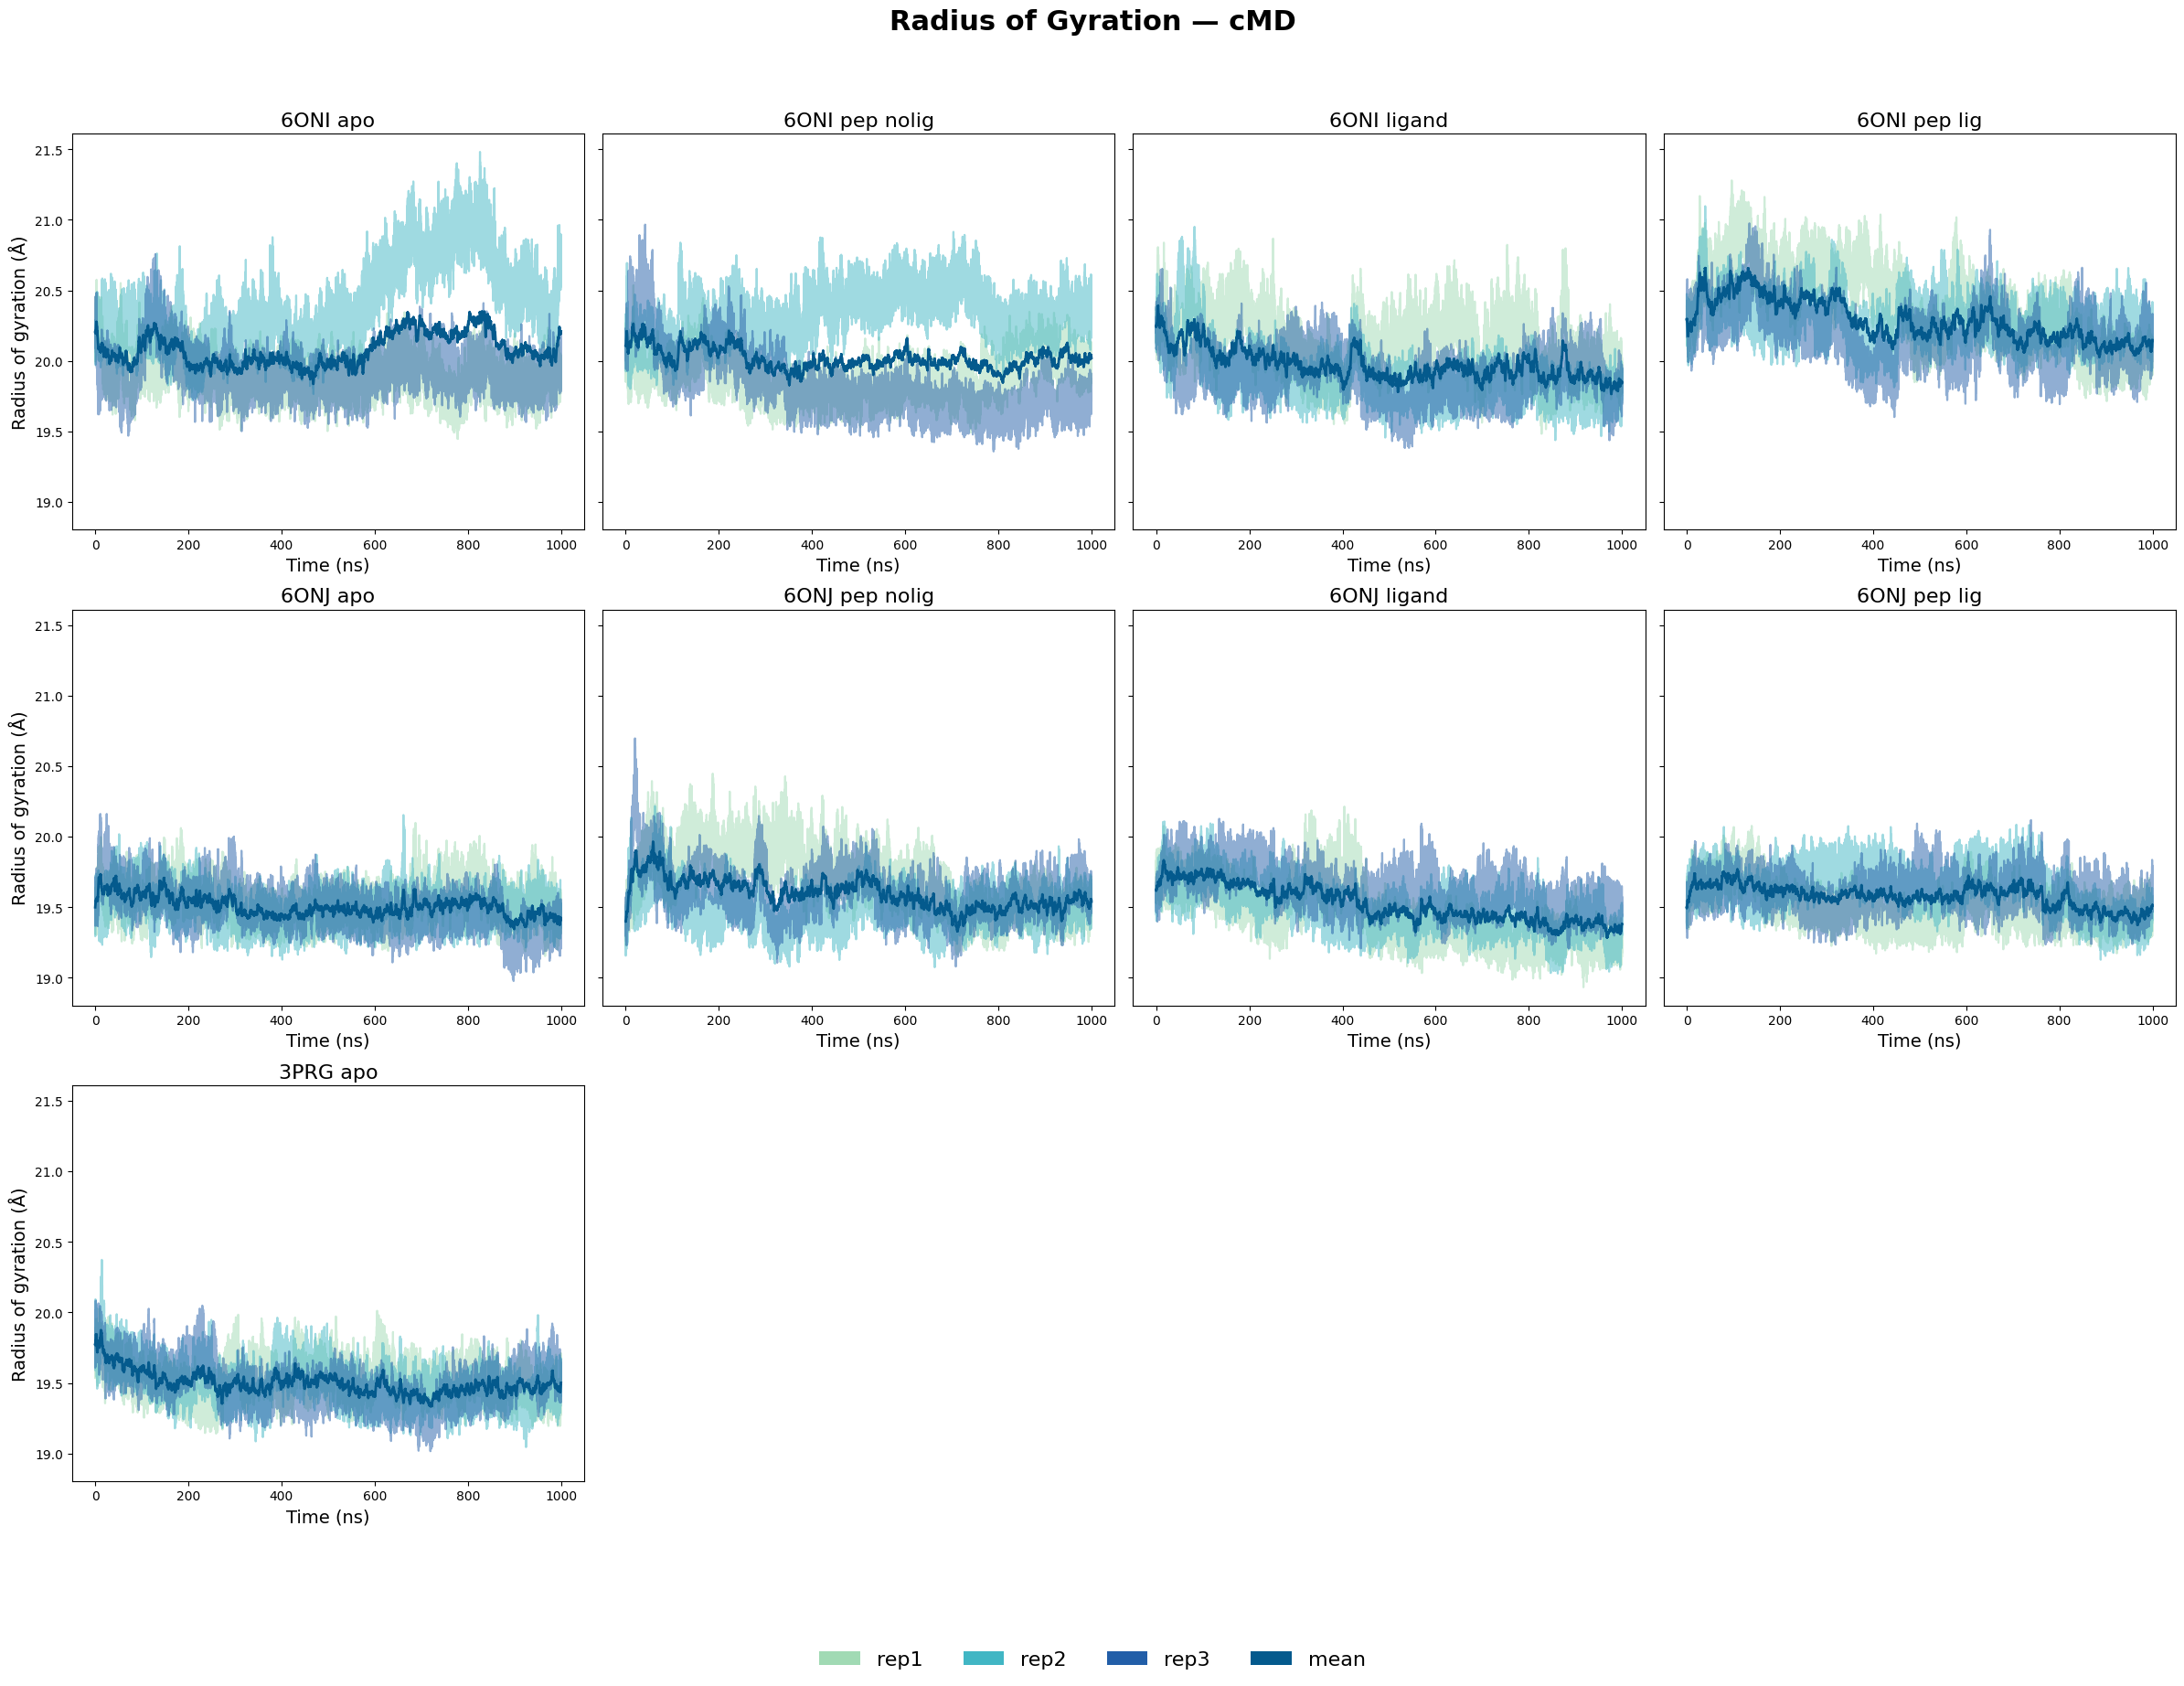

Saved: ./Plots/cMD/Rg_cMD.svg


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
from matplotlib.patches import Patch

FONT_SIZE_AXIS   = 14
FONT_SIZE_TITLE  = 16
FONT_SIZE_LEGEND = 16
LINE_WIDTH_REPS  = 1.6
LINE_WIDTH_MEAN  = 2.0
SMOOTH_WINDOW    = 160
FIGSIZE          = (24, 18)

BASE    = "./cMD"
OUTPLOT = "./Plots/cMD"
os.makedirs(OUTPLOT, exist_ok=True)

systems_6ONI = ["6ONI_apo","6ONI_pep_nolig","6ONI_ligand","6ONI_pep_lig"]
systems_6ONJ = ["6ONJ_apo","6ONJ_pep_nolig","6ONJ_ligand","6ONJ_pep_lig"]

colors = ["#a1dab4", "#41b6c4", "#225ea8"]

def smooth(y, window=160):
    return pd.Series(y).rolling(window, center=True, min_periods=1).mean().values

def load_rg(system, rep):
    path = f"{BASE}/{system}/rep{rep}/Rg.dat"
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, usecols=[0,1])
    df.columns = ["Frame","Rg"]
    df["Frame"] = df["Frame"] / 100.0
    return df

fig, axes = plt.subplots(3, 4, figsize=FIGSIZE, sharey=True)

# ---------- 6ONI ----------
for col, system in enumerate(systems_6ONI):
    ax = axes[0,col]
    reps=[]
    for rep in [1,2,3]:
        df=load_rg(system,rep)
        if df is None: continue
        ax.plot(df["Frame"],df["Rg"],color=colors[rep-1],alpha=0.5,linewidth=LINE_WIDTH_REPS)
        reps.append(df["Rg"].values)
    if len(reps)==3:
        ax.plot(df["Frame"],smooth(np.mean(reps,axis=0)),
                color="#045a8d",linewidth=LINE_WIDTH_MEAN)
    ax.set_title(system.replace("_"," "),fontsize=FONT_SIZE_TITLE)
    ax.set_xlabel("Time (ns)",fontsize=FONT_SIZE_AXIS)
    if col==0: ax.set_ylabel("Radius of gyration (Å)",fontsize=FONT_SIZE_AXIS)

# ---------- 6ONJ ----------
for col, system in enumerate(systems_6ONJ):
    ax = axes[1,col]
    reps=[]
    for rep in [1,2,3]:
        df=load_rg(system,rep)
        if df is None: continue
        ax.plot(df["Frame"],df["Rg"],color=colors[rep-1],alpha=0.5,linewidth=LINE_WIDTH_REPS)
        reps.append(df["Rg"].values)
    if len(reps)==3:
        ax.plot(df["Frame"],smooth(np.mean(reps,axis=0)),
                color="#045a8d",linewidth=LINE_WIDTH_MEAN)
    ax.set_title(system.replace("_"," "),fontsize=FONT_SIZE_TITLE)
    ax.set_xlabel("Time (ns)",fontsize=FONT_SIZE_AXIS)
    if col==0: ax.set_ylabel("Radius of gyration (Å)",fontsize=FONT_SIZE_AXIS)

# ---------- 3PRG ----------
ax = axes[2,0]
reps=[]
for rep in [1,2,3]:
    df=load_rg("3PRG",rep)
    if df is None: continue
    ax.plot(df["Frame"],df["Rg"],color=colors[rep-1],alpha=0.5,linewidth=LINE_WIDTH_REPS)
    reps.append(df["Rg"].values)
if len(reps)==3:
    ax.plot(df["Frame"],smooth(np.mean(reps,axis=0)),
            color="#045a8d",linewidth=LINE_WIDTH_MEAN)
ax.set_title("3PRG apo",fontsize=FONT_SIZE_TITLE)
ax.set_xlabel("Time (ns)",fontsize=FONT_SIZE_AXIS)
ax.set_ylabel("Radius of gyration (Å)",fontsize=FONT_SIZE_AXIS)

for j in [1,2,3]:
    axes[2,j].axis("off")

legend_patches=[
    Patch(facecolor=colors[0],label="rep1"),
    Patch(facecolor=colors[1],label="rep2"),
    Patch(facecolor=colors[2],label="rep3"),
    Patch(facecolor="#045a8d",label="mean"),
]

fig.legend(handles=legend_patches,loc="lower center",
           fontsize=FONT_SIZE_LEGEND,ncol=4,frameon=False,
           bbox_to_anchor=(0.5,-0.04))

plt.suptitle("Radius of Gyration — cMD",fontsize=22,weight="bold")
plt.tight_layout(rect=[0,0.05,1,0.95])

svg_out=f"{OUTPLOT}/Rg_cMD.svg"
plt.savefig(svg_out,format="svg",bbox_inches="tight")
plt.show()

print("Saved:",svg_out)


## 📏 RMSD — cMD

Plots backbone RMSD time traces for all canonical MD systems:

- **6ONI**: apo, pep-nolig, ligand, pep-lig  
- **6ONJ**: apo, pep-nolig, ligand, pep-lig  
- **3PRG**: apo

Each panel shows:
- Individual replicas (**rep1–rep3**)
- Smoothed mean trace (rolling window = 160 frames)

**Input:** `cMD/<system>/repX/RMSD.dat`  
**Time unit:** ns (frames ÷ 100)  
**Output:** `Plots/cMD/RMSD_cMD.svg`


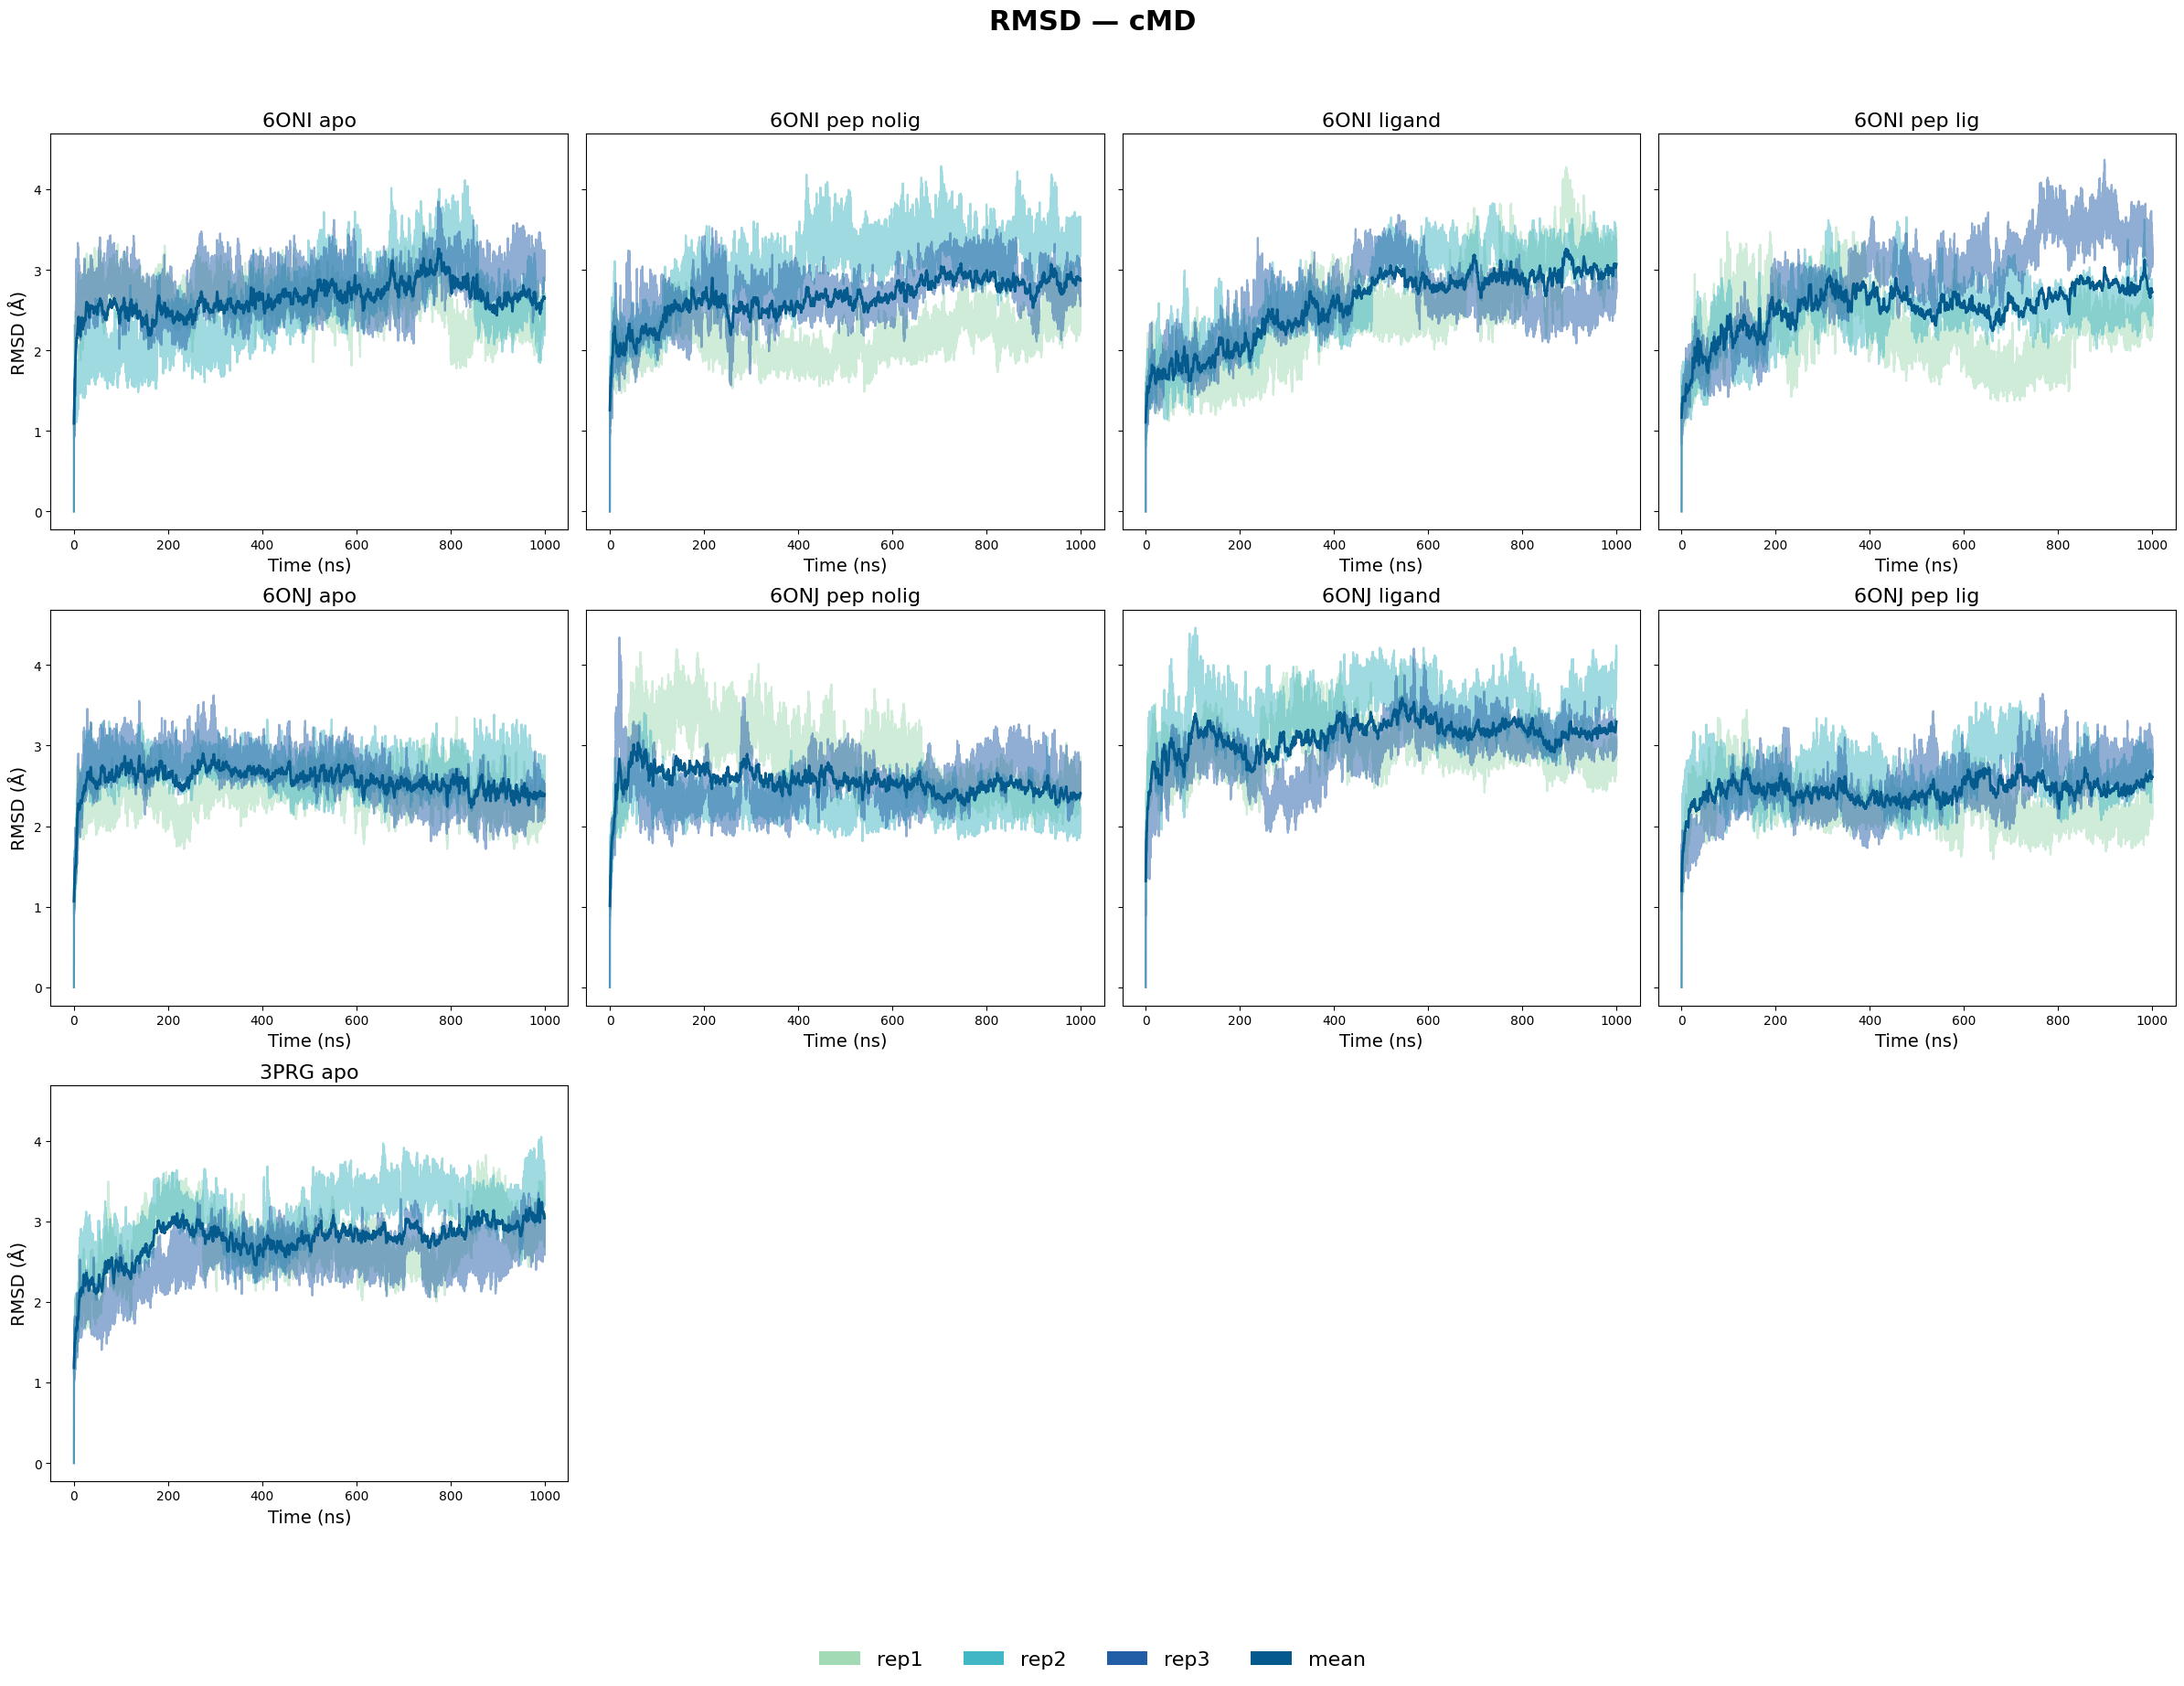

Saved: ./Plots/cMD/RMSD_cMD.svg


In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
from matplotlib.patches import Patch

FONT_SIZE_AXIS   = 14
FONT_SIZE_TITLE  = 16
FONT_SIZE_LEGEND = 16
LINE_WIDTH_REPS  = 1.6
LINE_WIDTH_MEAN  = 2.0
SMOOTH_WINDOW    = 160
FIGSIZE          = (24, 18)

BASE    = "./cMD"
OUTPLOT = "./Plots/cMD"
os.makedirs(OUTPLOT, exist_ok=True)

systems_6ONI = ["6ONI_apo","6ONI_pep_nolig","6ONI_ligand","6ONI_pep_lig"]
systems_6ONJ = ["6ONJ_apo","6ONJ_pep_nolig","6ONJ_ligand","6ONJ_pep_lig"]

colors = ["#a1dab4", "#41b6c4", "#225ea8"]

def smooth(y, window=160):
    return pd.Series(y).rolling(window, center=True, min_periods=1).mean().values

def load_rmsd(system, rep):
    path = f"{BASE}/{system}/rep{rep}/RMSD.dat"
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path, sep=r"\s+", comment="#", header=None, usecols=[0,1])
    df.columns = ["Frame","RMSD"]
    df["Frame"] = df["Frame"] / 100.0
    return df

fig, axes = plt.subplots(3, 4, figsize=FIGSIZE, sharey=True)

# ---------- 6ONI ----------
for col, system in enumerate(systems_6ONI):
    ax = axes[0,col]
    reps=[]
    for rep in [1,2,3]:
        df=load_rmsd(system,rep)
        if df is None: continue
        ax.plot(df["Frame"],df["RMSD"],color=colors[rep-1],alpha=0.5,linewidth=LINE_WIDTH_REPS)
        reps.append(df["RMSD"].values)
    if len(reps)==3:
        ax.plot(df["Frame"],smooth(np.mean(reps,axis=0)),color="#045a8d",linewidth=LINE_WIDTH_MEAN)
    ax.set_title(system.replace("_"," "),fontsize=FONT_SIZE_TITLE)
    ax.set_xlabel("Time (ns)",fontsize=FONT_SIZE_AXIS)
    if col==0: ax.set_ylabel("RMSD (Å)",fontsize=FONT_SIZE_AXIS)

# ---------- 6ONJ ----------
for col, system in enumerate(systems_6ONJ):
    ax = axes[1,col]
    reps=[]
    for rep in [1,2,3]:
        df=load_rmsd(system,rep)
        if df is None: continue
        ax.plot(df["Frame"],df["RMSD"],color=colors[rep-1],alpha=0.5,linewidth=LINE_WIDTH_REPS)
        reps.append(df["RMSD"].values)
    if len(reps)==3:
        ax.plot(df["Frame"],smooth(np.mean(reps,axis=0)),color="#045a8d",linewidth=LINE_WIDTH_MEAN)
    ax.set_title(system.replace("_"," "),fontsize=FONT_SIZE_TITLE)
    ax.set_xlabel("Time (ns)",fontsize=FONT_SIZE_AXIS)
    if col==0: ax.set_ylabel("RMSD (Å)",fontsize=FONT_SIZE_AXIS)

# ---------- 3PRG ----------
ax = axes[2,0]
reps=[]
for rep in [1,2,3]:
    df=load_rmsd("3PRG",rep)
    if df is None: continue
    ax.plot(df["Frame"],df["RMSD"],color=colors[rep-1],alpha=0.5,linewidth=LINE_WIDTH_REPS)
    reps.append(df["RMSD"].values)
if len(reps)==3:
    ax.plot(df["Frame"],smooth(np.mean(reps,axis=0)),color="#045a8d",linewidth=LINE_WIDTH_MEAN)
ax.set_title("3PRG apo",fontsize=FONT_SIZE_TITLE)
ax.set_xlabel("Time (ns)",fontsize=FONT_SIZE_AXIS)
ax.set_ylabel("RMSD (Å)",fontsize=FONT_SIZE_AXIS)

for j in [1,2,3]:
    axes[2,j].axis("off")

legend_patches=[
    Patch(facecolor=colors[0],label="rep1"),
    Patch(facecolor=colors[1],label="rep2"),
    Patch(facecolor=colors[2],label="rep3"),
    Patch(facecolor="#045a8d",label="mean"),
]

fig.legend(handles=legend_patches,loc="lower center",
           fontsize=FONT_SIZE_LEGEND,ncol=4,frameon=False,
           bbox_to_anchor=(0.5,-0.04))

plt.suptitle("RMSD — cMD",fontsize=22,weight="bold")
plt.tight_layout(rect=[0,0.05,1,0.95])

svg_out=f"{OUTPLOT}/RMSD_cMD.svg"
plt.savefig(svg_out,format="svg",bbox_inches="tight")
plt.show()

print("Saved:",svg_out)


## 📊 RMSF — cMD

Plots per-residue RMSF profiles for all canonical MD systems:

- **6ONI**: apo, pep-nolig, ligand, pep-lig  
- **6ONJ**: apo, pep-nolig, ligand, pep-lig  
- **3PRG**: apo

Each panel shows:
- Individual replicas (**rep1–rep3**) as separate colored traces  
- Residue numbering shifted by **+230** to match full-length indexing

**Input:** `cMD/<system>/repX/RMSF.dat`  
**Output:** `Plots/cMD/RMSF_cMD.svg`


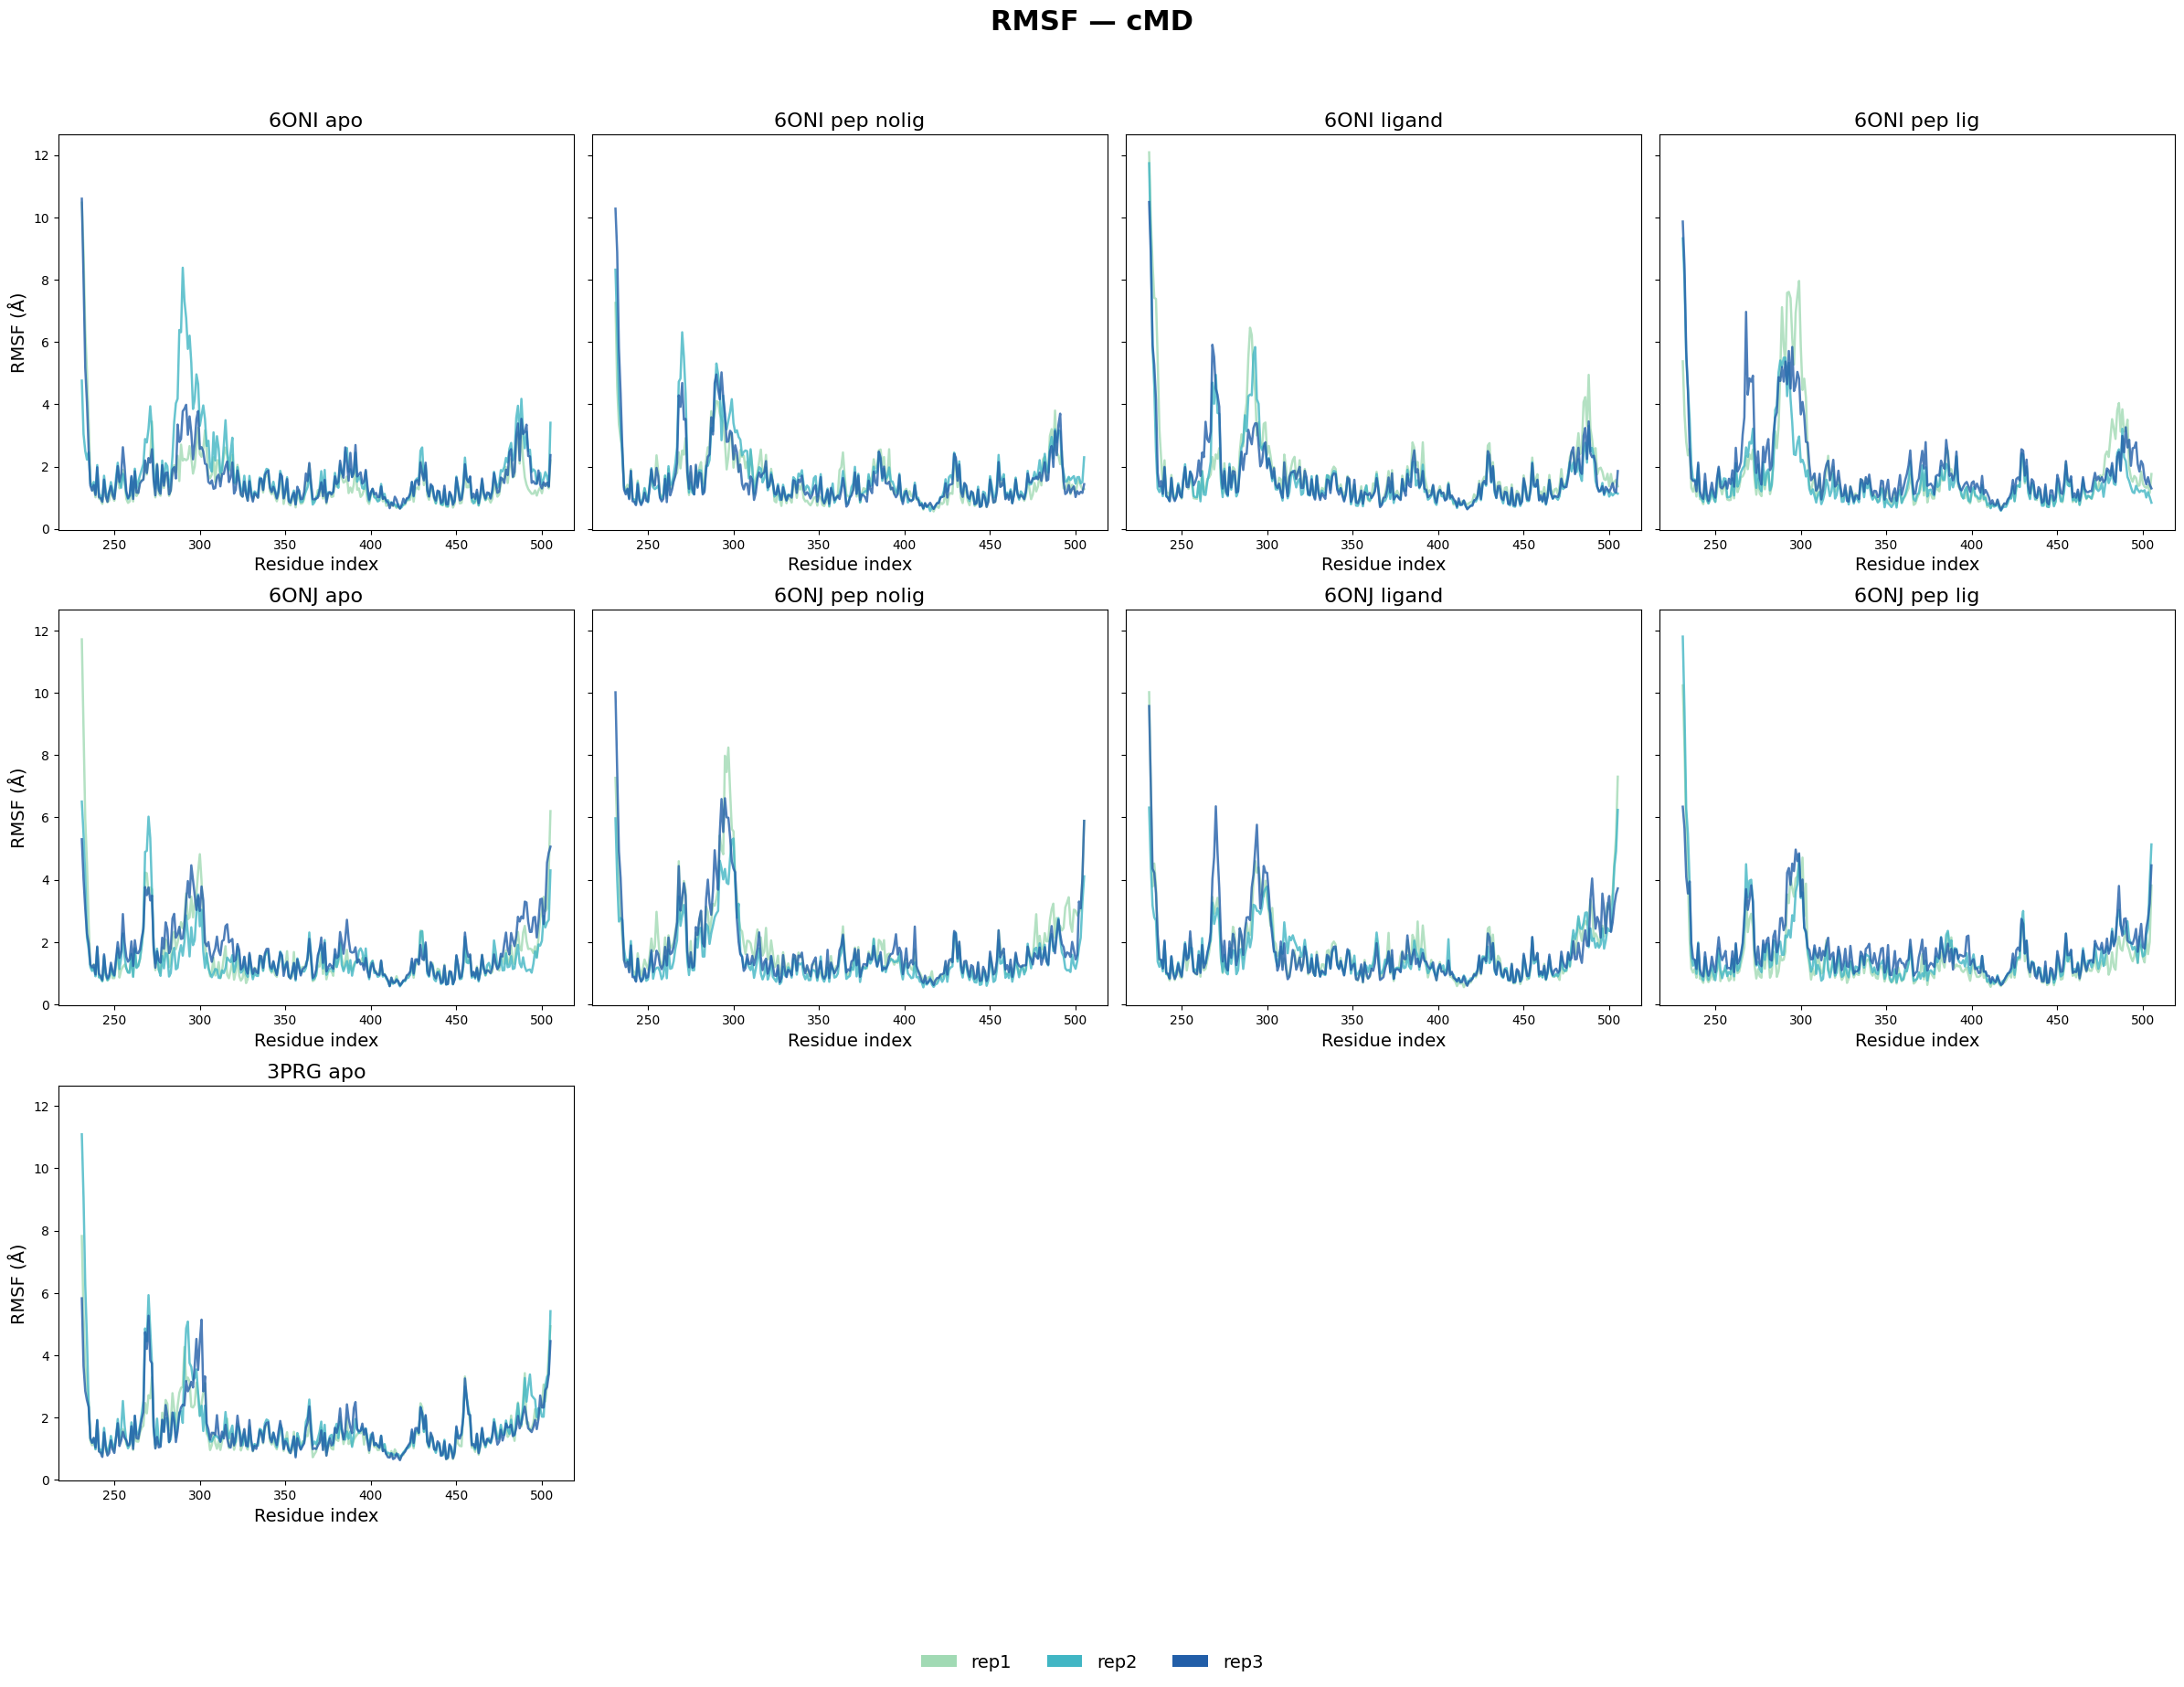

Saved: ./Plots/cMD/RMSF_cMD.svg


In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
from matplotlib.patches import Patch

FONT_SIZE_AXIS   = 14
FONT_SIZE_TITLE  = 16
FONT_SIZE_LEGEND = 14
LINE_WIDTH_REPS  = 1.8
FIGSIZE          = (24, 18)
ALPHA_REPS       = 0.8

BASE    = "./cMD"
OUTPLOT = "./Plots/cMD"
os.makedirs(OUTPLOT, exist_ok=True)

systems_6ONI = ["6ONI_apo","6ONI_pep_nolig","6ONI_ligand","6ONI_pep_lig"]
systems_6ONJ = ["6ONJ_apo","6ONJ_pep_nolig","6ONJ_ligand","6ONJ_pep_lig"]

colors = ["#a1dab4", "#41b6c4", "#225ea8"]

def load_rmsf(system, rep):
    path = f"{BASE}/{system}/rep{rep}/RMSF.dat"
    if not os.path.exists(path):
        return None
    return pd.read_csv(path, sep=r"\s+", comment="#", names=["Resid","RMSF"])

fig, axes = plt.subplots(3, 4, figsize=FIGSIZE, sharey=True)

# ---------- 6ONI ----------
for col, system in enumerate(systems_6ONI):
    ax = axes[0,col]
    for rep in [1,2,3]:
        df=load_rmsf(system,rep)
        if df is None: continue
        ax.plot(df["Resid"]+230, df["RMSF"],
                color=colors[rep-1], alpha=ALPHA_REPS,
                linewidth=LINE_WIDTH_REPS)
    ax.set_title(system.replace("_"," "),fontsize=FONT_SIZE_TITLE)
    ax.set_xlabel("Residue index",fontsize=FONT_SIZE_AXIS)
    if col==0: ax.set_ylabel("RMSF (Å)",fontsize=FONT_SIZE_AXIS)

# ---------- 6ONJ ----------
for col, system in enumerate(systems_6ONJ):
    ax = axes[1,col]
    for rep in [1,2,3]:
        df=load_rmsf(system,rep)
        if df is None: continue
        ax.plot(df["Resid"]+230, df["RMSF"],
                color=colors[rep-1], alpha=ALPHA_REPS,
                linewidth=LINE_WIDTH_REPS)
    ax.set_title(system.replace("_"," "),fontsize=FONT_SIZE_TITLE)
    ax.set_xlabel("Residue index",fontsize=FONT_SIZE_AXIS)
    if col==0: ax.set_ylabel("RMSF (Å)",fontsize=FONT_SIZE_AXIS)

# ---------- 3PRG ----------
ax = axes[2,0]
for rep in [1,2,3]:
    df=load_rmsf("3PRG",rep)
    if df is None: continue
    ax.plot(df["Resid"]+230, df["RMSF"],
            color=colors[rep-1], alpha=ALPHA_REPS,
            linewidth=LINE_WIDTH_REPS)

ax.set_title("3PRG apo",fontsize=FONT_SIZE_TITLE)
ax.set_xlabel("Residue index",fontsize=FONT_SIZE_AXIS)
ax.set_ylabel("RMSF (Å)",fontsize=FONT_SIZE_AXIS)

for j in [1,2,3]:
    axes[2,j].axis("off")

legend_patches=[
    Patch(facecolor=colors[0],label="rep1"),
    Patch(facecolor=colors[1],label="rep2"),
    Patch(facecolor=colors[2],label="rep3")
]

fig.legend(handles=legend_patches,loc="lower center",
           fontsize=FONT_SIZE_LEGEND,ncol=3,frameon=False,
           bbox_to_anchor=(0.5,-0.04))

plt.suptitle("RMSF — cMD",fontsize=22,weight="bold")
plt.tight_layout(rect=[0,0.05,1,0.95])

svg_out=f"{OUTPLOT}/RMSF_cMD.svg"
plt.savefig(svg_out,format="svg",bbox_inches="tight")
plt.show()

print("Saved:",svg_out)


## 🌊 SASA Density — cMD

Plots kernel-density estimates (KDEs) of protein solvent-accessible surface area (SASA)
for all canonical MD systems:

- **6ONI**: apo, pep-nolig, ligand, pep-lig  
- **6ONJ**: apo, pep-nolig, ligand, pep-lig  
- **3PRG**: apo

Each panel shows:
- KDE curves for individual replicas (**rep1–rep3**) with shaded density
- Common global SASA range across all systems for direct comparison

**Input:** `cMD/<system>/repX/SASA.dat`  
**Output:** `Plots/cMD/SASA_cMD.svg`


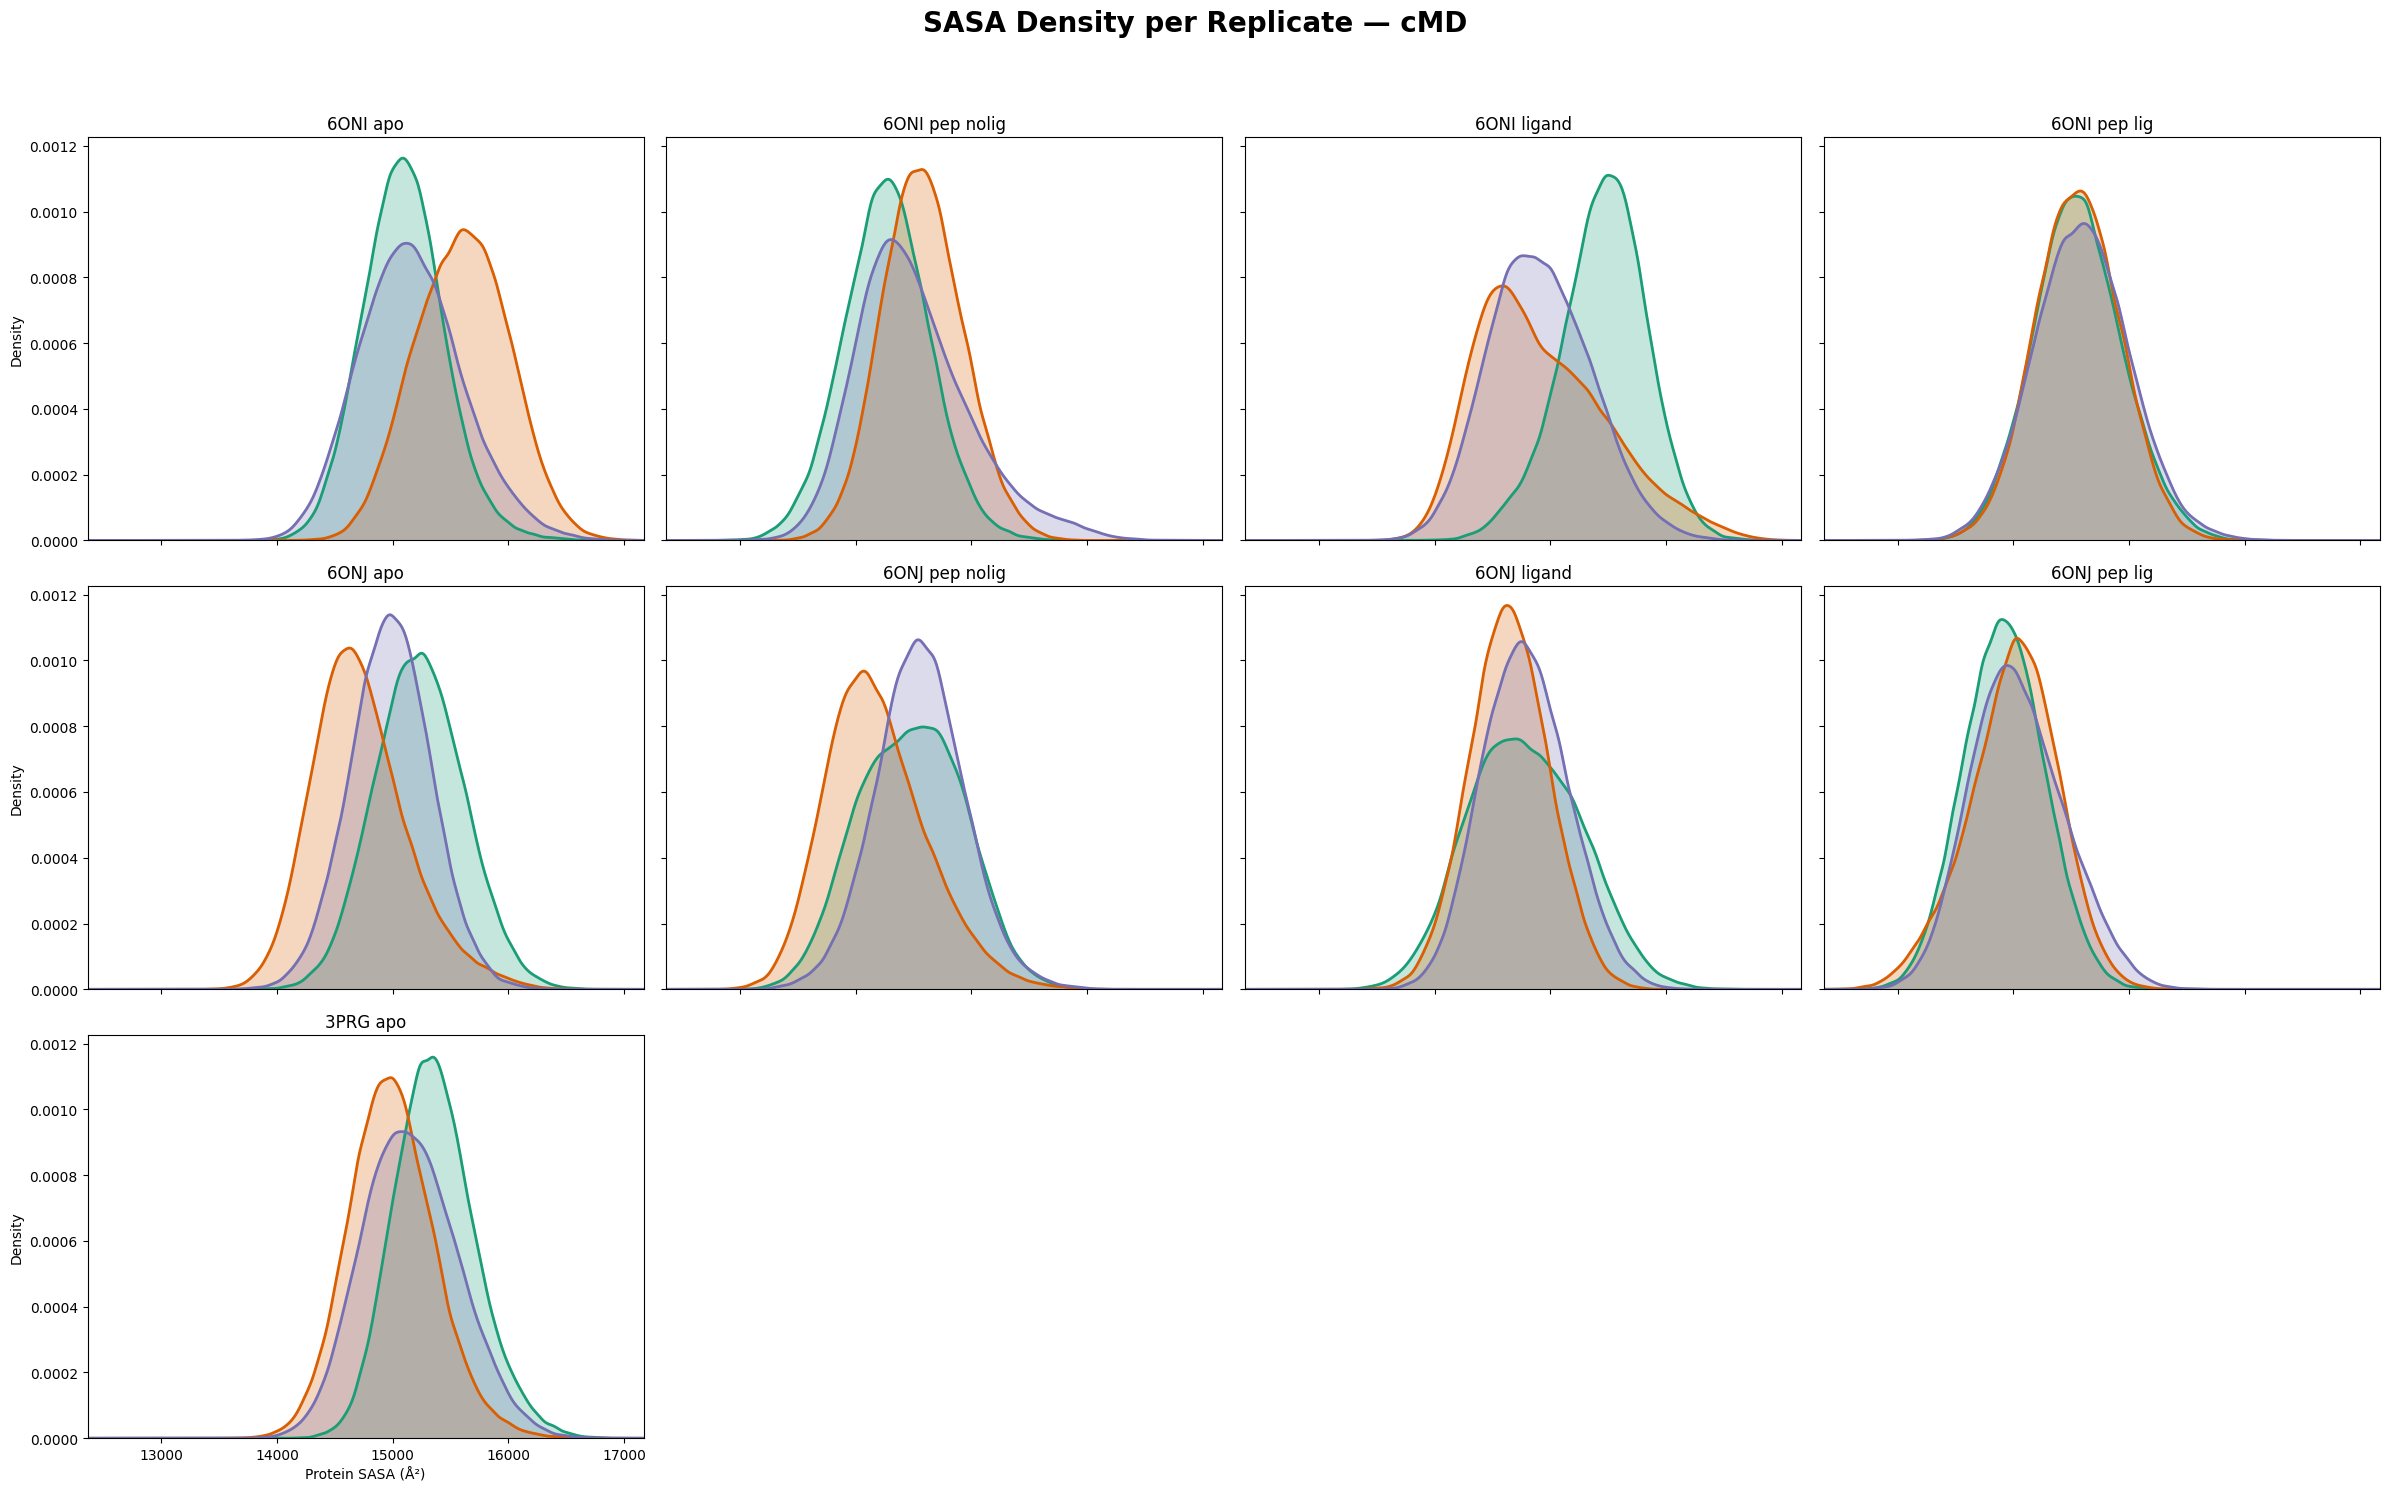

Saved: ./Plots/cMD/SASA_cMD.svg


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.stats import gaussian_kde

BASE = "./cMD"
OUTPLOT = "./Plots/cMD"
os.makedirs(OUTPLOT, exist_ok=True)

systems_6ONI = ["6ONI_apo","6ONI_pep_nolig","6ONI_ligand","6ONI_pep_lig"]
systems_6ONJ = ["6ONJ_apo","6ONJ_pep_nolig","6ONJ_ligand","6ONJ_pep_lig"]

colors = ["#1b9e77", "#d95f02", "#7570b3"]

def load_sasa(system, rep):
    f = f"{BASE}/{system}/rep{rep}/SASA.dat"
    if not os.path.isfile(f):
        return None
    df = pd.read_csv(f, sep=r"\s+", comment="#", header=None, usecols=[1])
    return df.iloc[:,0].values

# ---------- LOAD ALL DATA ----------
all_data = {}
global_min, global_max = np.inf, -np.inf

for sys in systems_6ONI + systems_6ONJ + ["3PRG"]:
    for rep in [1,2,3]:
        data = load_sasa(sys, rep)
        if data is None: continue
        all_data[(sys,rep)] = data
        global_min = min(global_min, data.min())
        global_max = max(global_max, data.max())

x_global = np.linspace(global_min, global_max, 600)

# ---------- COMPUTE KDEs ----------
kdes = {}
global_ymax = 0
for (sys,rep), data in all_data.items():
    kde = gaussian_kde(data)
    y = kde(x_global)
    kdes[(sys,rep)] = y
    global_ymax = max(global_ymax, y.max())

# ---------- PLOT GRID ----------
fig, axes = plt.subplots(3, 4, figsize=(24,16), sharex=True, sharey=True)

# 6ONI row
for col, system in enumerate(systems_6ONI):
    ax = axes[0,col]
    for rep in [1,2,3]:
        if (system,rep) not in kdes: continue
        y = kdes[(system,rep)]
        ax.plot(x_global, y, color=colors[rep-1], linewidth=2)
        ax.fill_between(x_global, y, alpha=0.25, color=colors[rep-1])
    ax.set_title(system.replace("_"," "))
    if col==0: ax.set_ylabel("Density")

# 6ONJ row
for col, system in enumerate(systems_6ONJ):
    ax = axes[1,col]
    for rep in [1,2,3]:
        if (system,rep) not in kdes: continue
        y = kdes[(system,rep)]
        ax.plot(x_global, y, color=colors[rep-1], linewidth=2)
        ax.fill_between(x_global, y, alpha=0.25, color=colors[rep-1])
    ax.set_title(system.replace("_"," "))
    if col==0: ax.set_ylabel("Density")

# 3PRG row (single panel)
ax = axes[2,0]
for rep in [1,2,3]:
    if ("3PRG",rep) not in kdes: continue
    y = kdes[("3PRG",rep)]
    ax.plot(x_global, y, color=colors[rep-1], linewidth=2)
    ax.fill_between(x_global, y, alpha=0.25, color=colors[rep-1])
ax.set_title("3PRG apo")
ax.set_ylabel("Density")
ax.set_xlabel("Protein SASA (Å²)")

for j in [1,2,3]:
    axes[2,j].axis("off")

plt.xlim(global_min, global_max)
plt.ylim(0, global_ymax * 1.05)

plt.suptitle("SASA Density per Replicate — cMD", fontsize=20, weight="bold")
plt.tight_layout(rect=[0,0.05,1,0.95])

out = f"{OUTPLOT}/SASA_cMD.svg"
plt.savefig(out, format="svg")
plt.show()

print("Saved:", out)


## 🌊 Grouped SASA Density — cMD

Plots kernel-density estimates (KDEs) of protein SASA by **ligand/peptide state**,
pooling all three replicas for each system.

**Rows:**
1. **6ONI** (apo, pep-nolig, ligand, pep-lig)  
2. **6ONJ** (apo, pep-nolig, ligand, pep-lig)  
3. **3PRG** (apo)

**Color scheme**
- apo – green  
- pep-nolig – orange  
- ligand – purple  
- pep-lig – pink  

**Input:** `cMD/<system>/rep1-3/SASA.dat`  
**Output:** `Plots/cMD/SASA_grouped_cMD.svg`


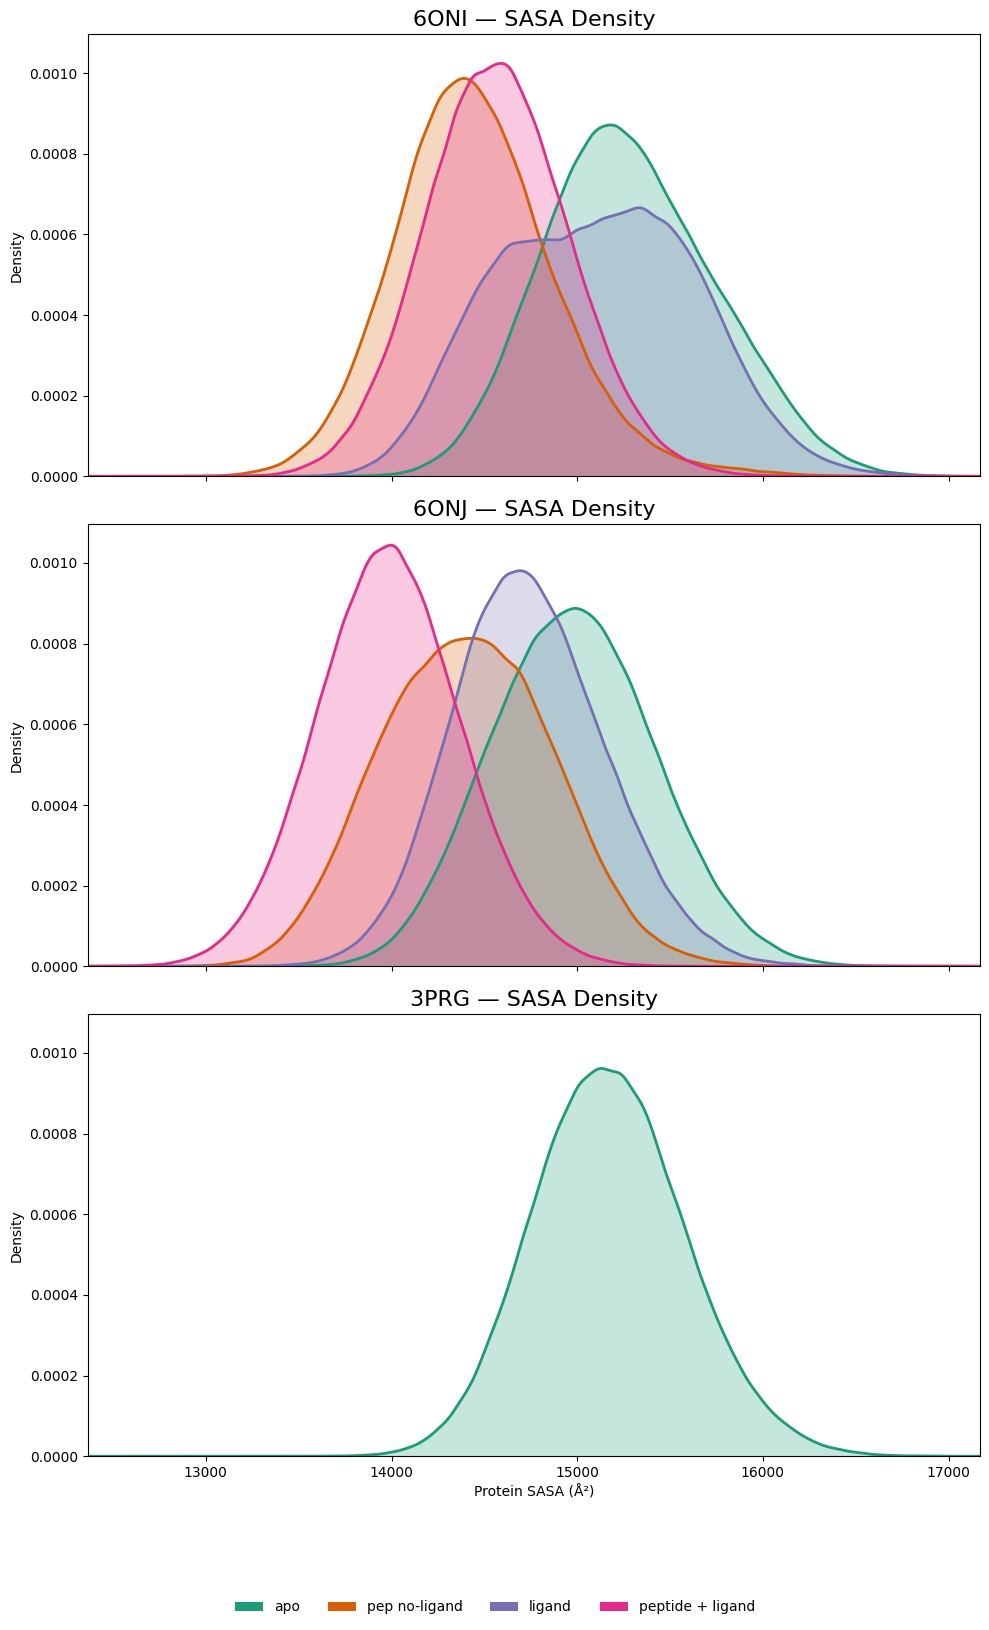

Saved: ./Plots/cMD/SASA_grouped_cMD.svg


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch

BASE = "./cMD"
OUTPLOT = "./Plots/cMD"
os.makedirs(OUTPLOT, exist_ok=True)

systems_6ONI = ["6ONI_apo","6ONI_pep_nolig","6ONI_ligand","6ONI_pep_lig"]
systems_6ONJ = ["6ONJ_apo","6ONJ_pep_nolig","6ONJ_ligand","6ONJ_pep_lig"]

color_map = {
    "apo": "#1b9e77",
    "pep_nolig": "#d95f02",
    "ligand": "#7570b3",
    "pep_lig": "#e7298a"
}

def load_sasa(system):
    vals=[]
    for rep in [1,2,3]:
        f=f"{BASE}/{system}/rep{rep}/SASA.dat"
        if os.path.isfile(f):
            df=pd.read_csv(f,sep=r"\s+",comment="#",header=None,usecols=[1])
            vals.extend(df.iloc[:,0].values)
    return np.array(vals)

# ---------- LOAD DATA ----------
all_data={}
global_min,global_max=np.inf,-np.inf

for sys in systems_6ONI+systems_6ONJ+["3PRG"]:
    d=load_sasa(sys)
    if len(d)==0: continue
    all_data[sys]=d
    global_min=min(global_min,d.min())
    global_max=max(global_max,d.max())

x_global=np.linspace(global_min,global_max,600)

kdes={}
global_ymax=0
for sys,d in all_data.items():
    kde=gaussian_kde(d)
    y=kde(x_global)
    kdes[sys]=y
    global_ymax=max(global_ymax,y.max())

# ---------- FIGURE ----------
fig,axes=plt.subplots(3,1,figsize=(10,16),sharex=True,sharey=True)

def system_key(sys):
    return sys.replace("6ONI_","").replace("6ONJ_","")

def plot_group(ax,systems,title):
    for sys in systems:
        key=system_key(sys)
        if sys not in kdes: continue
        y=kdes[sys]
        ax.plot(x_global,y,color=color_map[key],linewidth=2)
        ax.fill_between(x_global,y,color=color_map[key],alpha=0.25)
    ax.set_title(title,fontsize=16)
    ax.set_ylabel("Density")

plot_group(axes[0],systems_6ONI,"6ONI — SASA Density")
plot_group(axes[1],systems_6ONJ,"6ONJ — SASA Density")

if "3PRG" in kdes:
    y=kdes["3PRG"]
    axes[2].plot(x_global,y,color="#1b9e77",linewidth=2)
    axes[2].fill_between(x_global,y,color="#1b9e77",alpha=0.25)

axes[2].set_title("3PRG — SASA Density",fontsize=16)
axes[2].set_ylabel("Density")
axes[2].set_xlabel("Protein SASA (Å²)")

plt.xlim(global_min,global_max)
plt.ylim(0,global_ymax*1.05)

legend_patches=[
    Patch(facecolor=color_map["apo"],label="apo"),
    Patch(facecolor=color_map["pep_nolig"],label="pep no-ligand"),
    Patch(facecolor=color_map["ligand"],label="ligand"),
    Patch(facecolor=color_map["pep_lig"],label="peptide + ligand"),
]

fig.legend(handles=legend_patches,loc="lower center",
           ncol=4,frameon=False,bbox_to_anchor=(0.5,-0.02))

plt.tight_layout(rect=[0,0.05,1,1])

out=f"{OUTPLOT}/SASA_grouped_cMD.svg"
plt.savefig(out,format="svg")
plt.show()

print("Saved:",out)


## 🧠 PCA Scree & Cumulative Variance — cMD

Generates per-replicate PCA scree plots showing the variance explained by the first
10 principal components for all canonical MD systems.

Each panel displays:
- **Bars**: individual PC eigenvalues (PC1–PC10)
- **Line + markers**: cumulative variance
- **Bold annotation**: total variance captured by **PC1 + PC2**

**Panels include:**
- 6ONI: apo, pep-nolig, ligand, pep-lig (rep1–rep3)
- 6ONJ: apo, pep-nolig, ligand, pep-lig (rep1–rep3)
- 3PRG reference (rep1–rep3)

**Input:** `cMD/<system>/repX/evecs.dat`  
**Output:** `Plots/cMD/PCA_PC_variance_percent.svg`


Saved: ./Plots/cMD/PCA_PC_variance_percent.svg


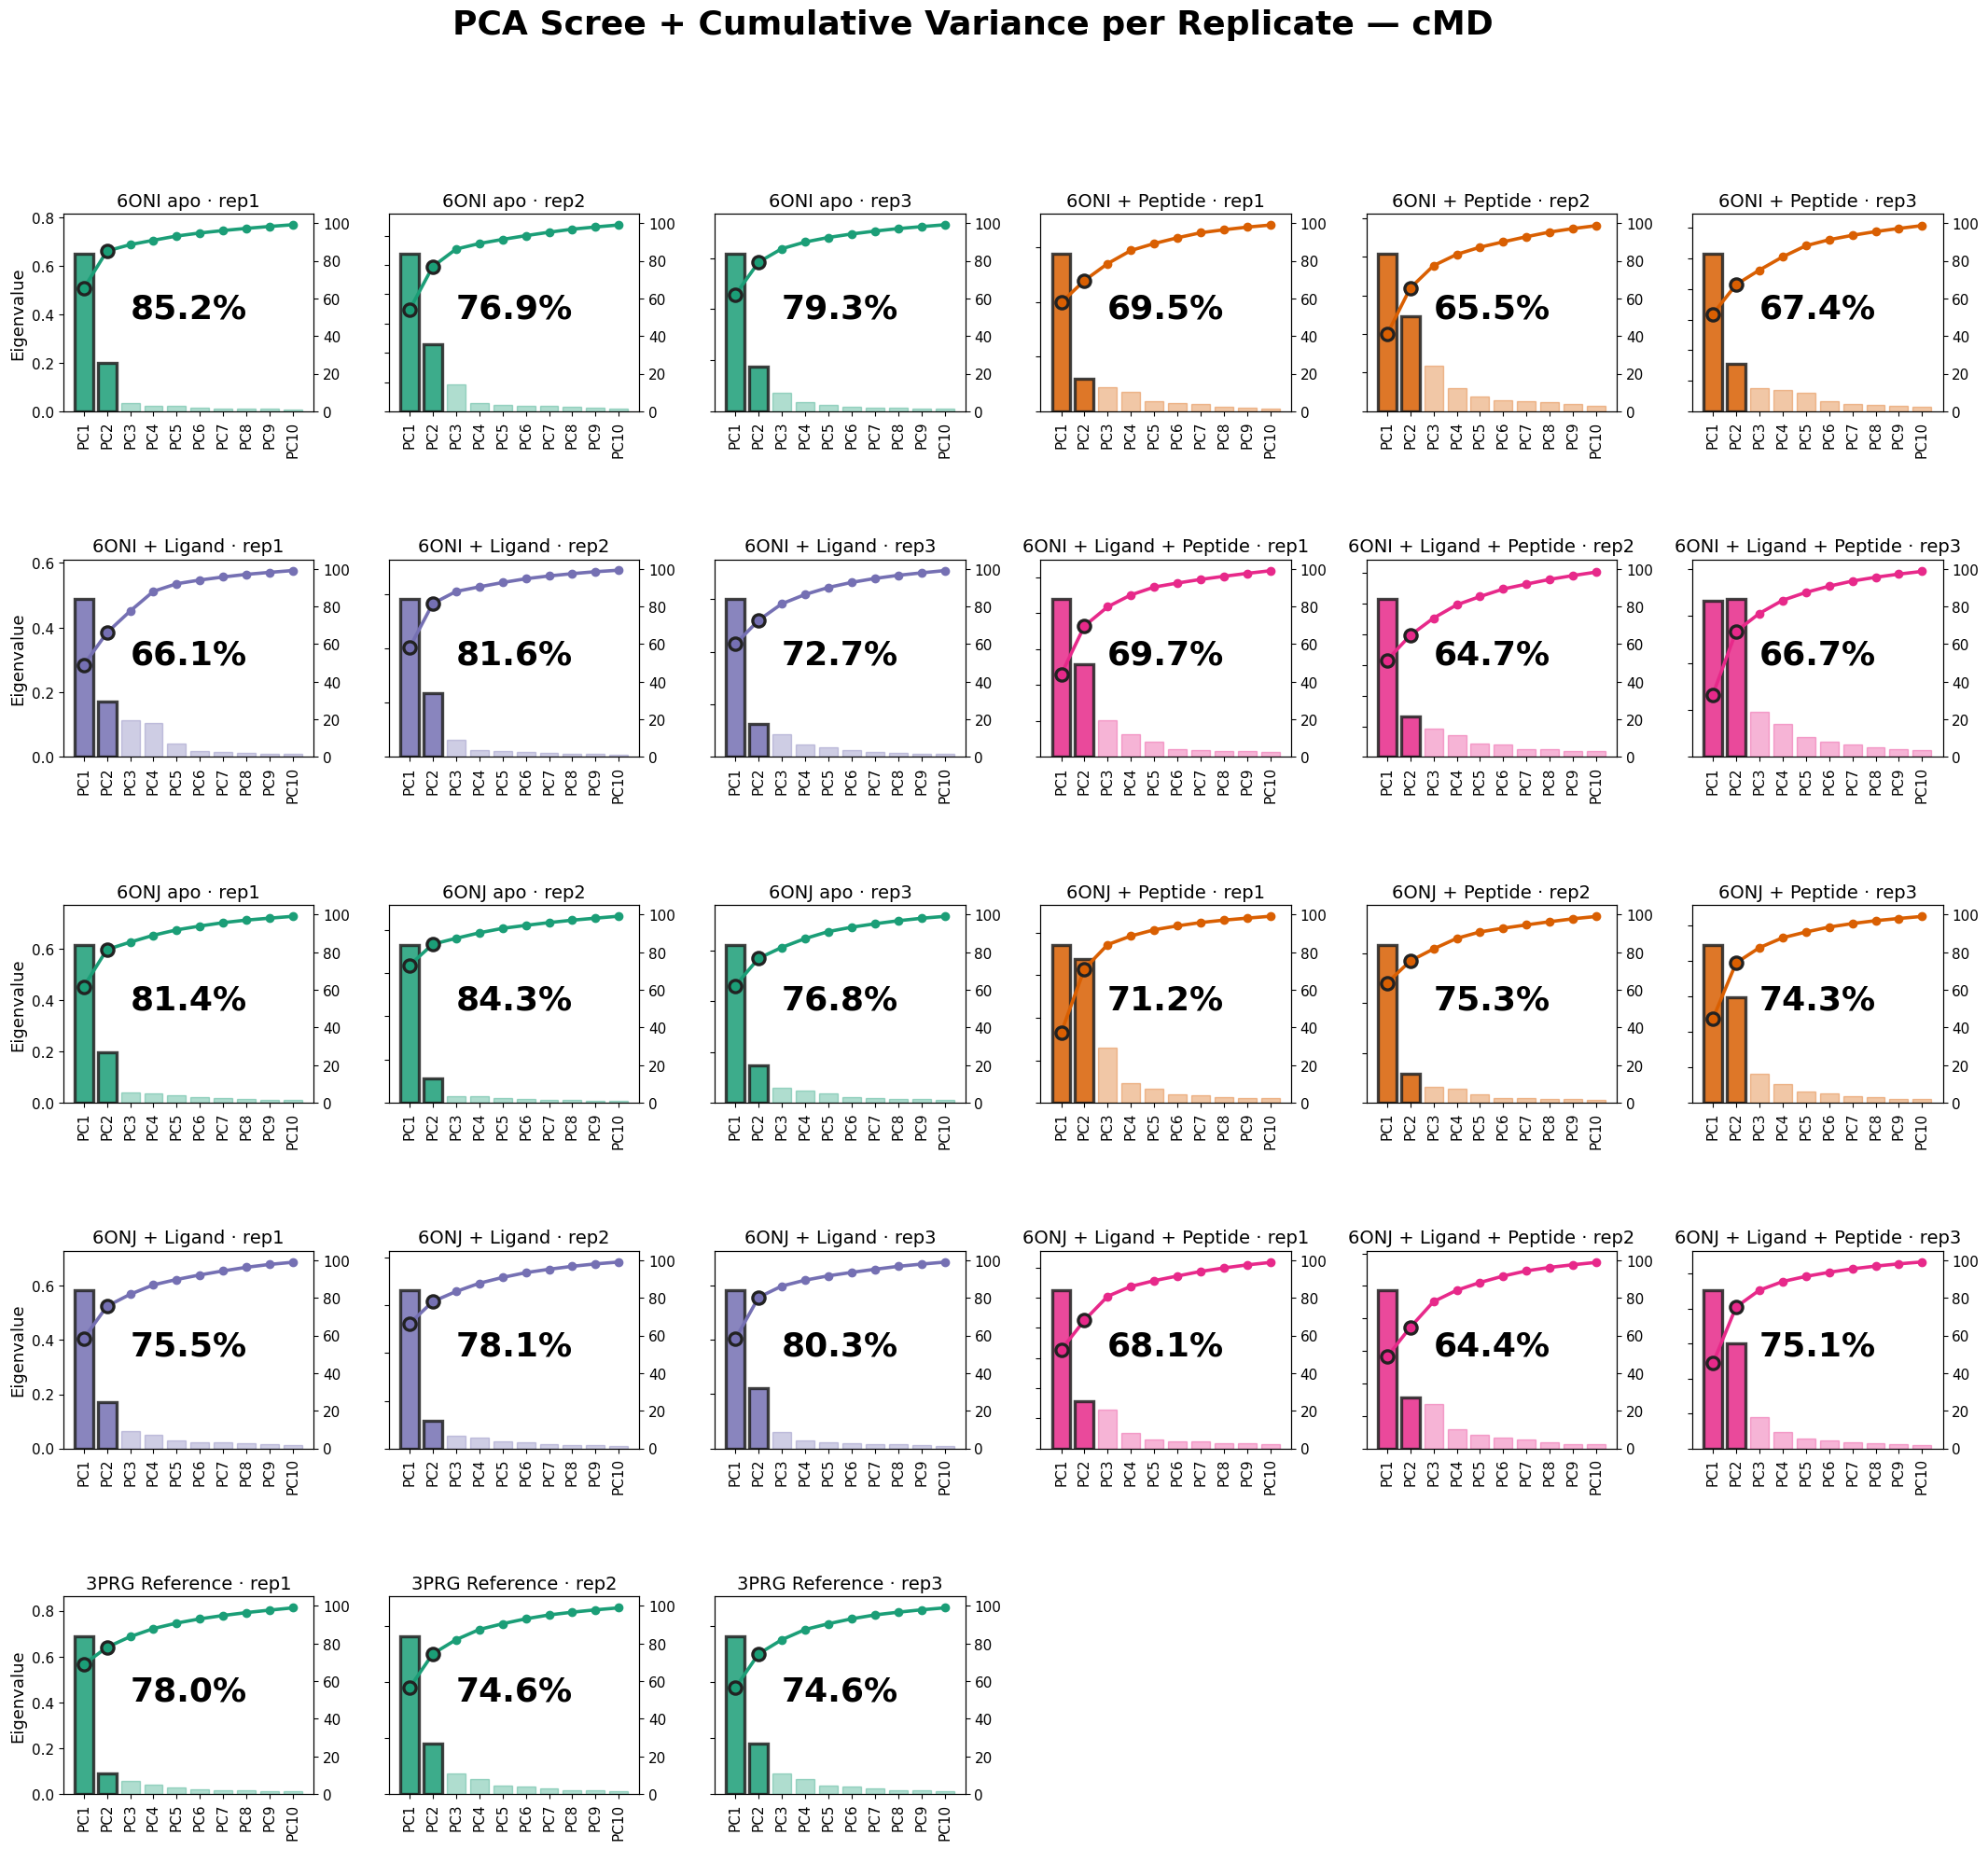

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import os, re

BASE = "./cMD"
OUT  = "./Plots/cMD"
os.makedirs(OUT, exist_ok=True)
SAVE_SVG = True

systems = [
    "6ONI_apo","6ONI_pep_nolig","6ONI_ligand","6ONI_pep_lig",
    "6ONJ_apo","6ONJ_pep_nolig","6ONJ_ligand","6ONJ_pep_lig",
    "3PRG"
]

colors = {
    "apo": "#1b9e77",
    "pep_nolig": "#d95f02",
    "ligand": "#7570b3",
    "pep_lig": "#e7298a",
    "3PRG": "#1b9e77"
}

HIGHLIGHT = "#222222"

SUPTITLE_FONT = 26
TITLE_FONT    = 14
LABEL_FONT    = 13
TICK_FONT     = 11

def pretty_title(sys):
    if sys == "3PRG":
        return "3PRG Reference"
    base = "6ONI" if sys.startswith("6ONI") else "6ONJ"
    if "apo" in sys:
        cond = "apo"
    elif "pep_nolig" in sys:
        cond = "+ Peptide"
    elif "ligand" in sys and "pep" not in sys:
        cond = "+ Ligand"
    elif "pep_lig" in sys:
        cond = "+ Ligand + Peptide"
    else:
        cond = ""
    return f"{base} {cond}"

def key(sys):
    if sys == "3PRG": return "3PRG"
    return sys.replace("6ONI_","").replace("6ONJ_","")

def load_evecs(system, rep):
    f = f"{BASE}/{system}/rep{rep}/evecs.dat"
    if not os.path.isfile(f):
        return None
    vals=[]
    with open(f) as fh:
        for l in fh:
            if re.match(r"^\s*\d+\s+[-+0-9.Ee]+", l):
                vals.append(float(l.split()[1]))
    if not vals: return None
    v=np.array(vals)
    return 100*v/v.sum()

panels=[]
for sys in systems:
    for rep in [1,2,3]:
        panels.append((sys,rep))

ncols = 6
nrows = int(np.ceil(len(panels)/ncols))

fig,axes = plt.subplots(nrows, ncols, figsize=(26,4.4*nrows))
axes = axes.flatten()

for idx,(ax,(sys,rep)) in enumerate(zip(axes,panels)):

    v = load_evecs(sys,rep)
    if v is None:
        ax.axis("off")
        continue

    col = idx % ncols
    c = colors[key(sys)]
    pcs = np.arange(1,len(v)+1)
    eig = v / 100.0

    bars = ax.bar(pcs[:10], eig[:10], color=c, alpha=0.35,
                  edgecolor=c, linewidth=1)

    for i in [0,1]:
        bars[i].set_edgecolor(HIGHLIGHT)
        bars[i].set_linewidth(2.4)
        bars[i].set_alpha(0.85)

    ax.set_ylim(0, max(eig[:10])*1.25)

    if col == 0:
        ax.set_ylabel("Eigenvalue", fontsize=LABEL_FONT)
        ax.tick_params(labelsize=TICK_FONT)
    else:
        ax.set_yticklabels([])
        ax.set_ylabel("")

    ax2 = ax.twinx()
    cum = np.cumsum(v)
    ax2.plot(pcs[:10], cum[:10], color=c, lw=2.6, marker="o")
    ax2.scatter(pcs[:2], cum[:2], s=90, facecolors=c,
                edgecolors=HIGHLIGHT, linewidths=2.4, zorder=5)
    ax2.set_ylim(0,105)
    ax2.tick_params(labelsize=TICK_FONT)

    ax.set_xticks(pcs[:10])
    ax.set_xticklabels([f"PC{i}" for i in pcs[:10]],
                       rotation=90, fontsize=TICK_FONT)

    ax2.text(5.5, 0.52*ax2.get_ylim()[1],
             f"{v[0]+v[1]:.1f}%",
             fontsize=26, weight="bold",
             ha="center", va="center")

    ax.set_title(f"{pretty_title(sys)} · rep{rep}", fontsize=TITLE_FONT)

for ax in axes[len(panels):]:
    ax.axis("off")

plt.suptitle("PCA Scree + Cumulative Variance per Replicate — cMD",
             fontsize=SUPTITLE_FONT, weight="bold")

plt.subplots_adjust(hspace=0.75, wspace=0.30)

if SAVE_SVG:
    out=f"{OUT}/PCA_PC_variance_percent.svg"
    plt.savefig(out,format="svg")
    print("Saved:",out)

plt.show()


## 🌀 PC1–PC2 Time-Gradient Projections — cMD

Generates per-replicate PC1 vs PC2 scatter plots with a **temporal color gradient**
to visualize conformational drift over time under canonical MD.

Each panel shows:
- Scatter of PC1 vs PC2 with points colored from light → dark to represent
  progression along the trajectory.
- **Star marker** indicating the starting frame.
- Globally shared PC1/PC2 axis limits for direct comparison across all systems.

**Panels include:**
- 6ONI: apo, pep-nolig, ligand, pep-lig (rep1–rep3)  
- 6ONJ: apo, pep-nolig, ligand, pep-lig (rep1–rep3)  
- 3PRG reference (rep1–rep3)

**Input:** `cMD/<system>/repX/PCA.dat`  
**Output:** `Plots/cMD/PC1_PC2_time_gradient_individual_plots.svg`


Saved: ./Plots/cMD/PC1_PC2_time_gradient_individual_plots.svg


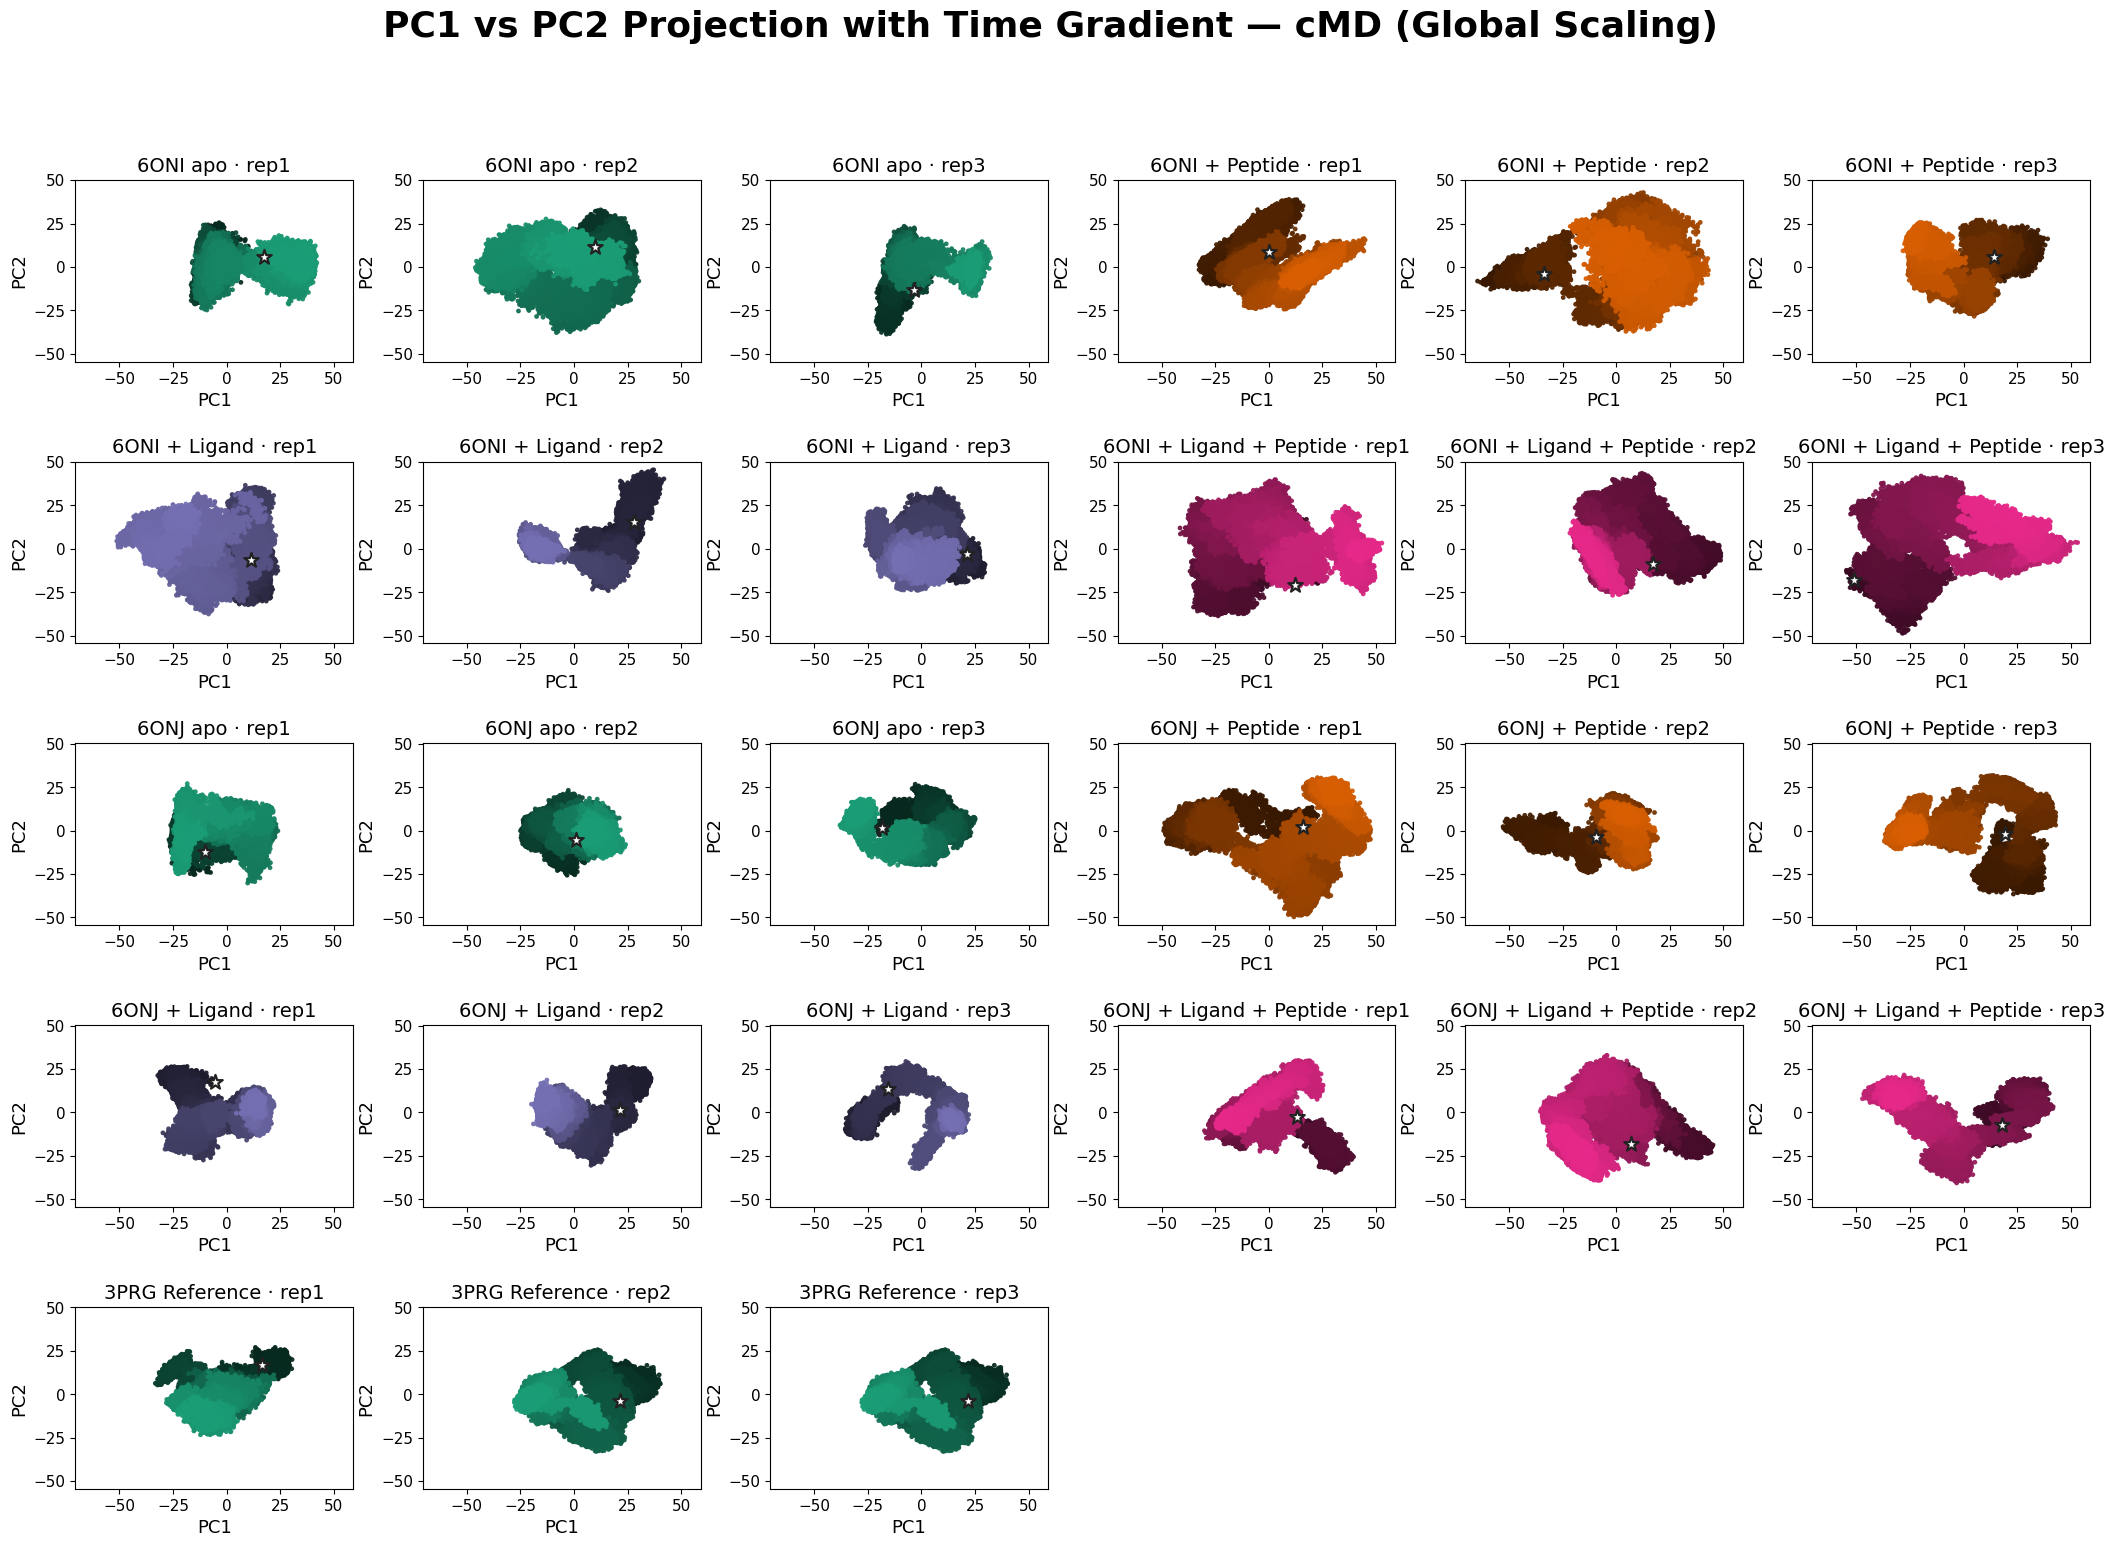

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib.colors import to_rgb

BASE = "./cMD"
OUT  = "./Plots/cMD"
os.makedirs(OUT, exist_ok=True)

SAVE_SVG = True

systems = [
    "6ONI_apo","6ONI_pep_nolig","6ONI_ligand","6ONI_pep_lig",
    "6ONJ_apo","6ONJ_pep_nolig","6ONJ_ligand","6ONJ_pep_lig",
    "3PRG"
]

colors = {
    "apo": "#1b9e77",
    "pep_nolig": "#d95f02",
    "ligand": "#7570b3",
    "pep_lig": "#e7298a",
    "3PRG": "#1b9e77"
}

SUPTITLE_FONT = 26
TITLE_FONT    = 14
LABEL_FONT    = 13
TICK_FONT     = 11

def pretty_title(sys):
    if sys == "3PRG":
        return "3PRG Reference"

    base = "6ONI" if sys.startswith("6ONI") else "6ONJ"

    if "apo" in sys:
        cond = "apo"
    elif "pep_nolig" in sys:
        cond = "+ Peptide"
    elif "ligand" in sys and "pep" not in sys:
        cond = "+ Ligand"
    elif "pep_lig" in sys:
        cond = "+ Ligand + Peptide"
    else:
        cond = ""

    return f"{base} {cond}"

def key(sys):
    if sys == "3PRG": return "3PRG"
    return sys.replace("6ONI_","").replace("6ONJ_","")

def load_pca(system, rep):
    f = f"{BASE}/{system}/rep{rep}/PCA.dat"
    if not os.path.isfile(f):
        return None
    data = np.loadtxt(f)
    return data[:,1], data[:,2]

def gradient_colors(base_color, n):
    r,g,b = to_rgb(base_color)
    t = np.linspace(0.25, 1.0, n)
    return np.column_stack([r*t, g*t, b*t])

# ---------- global limits ----------
all_pc1, all_pc2 = [], []
for sys in systems:
    for rep in [1,2,3]:
        d = load_pca(sys,rep)
        if d is None: continue
        all_pc1.append(d[0])
        all_pc2.append(d[1])

PC1_MIN = min(map(np.min, all_pc1))
PC1_MAX = max(map(np.max, all_pc1))
PC2_MIN = min(map(np.min, all_pc2))
PC2_MAX = max(map(np.max, all_pc2))

pad1 = 0.05*(PC1_MAX-PC1_MIN)
pad2 = 0.05*(PC2_MAX-PC2_MIN)
PC1_MIN -= pad1; PC1_MAX += pad1
PC2_MIN -= pad2; PC2_MAX += pad2

# ---------- build panels ----------
panels=[]
for sys in systems:
    for rep in [1,2,3]:
        panels.append((sys,rep))

ncols = 6
nrows = int(np.ceil(len(panels)/ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(26,3.4*nrows))
axes = axes.flatten()

for ax,(sys,rep) in zip(axes,panels):

    d = load_pca(sys,rep)
    if d is None:
        ax.axis("off")
        continue

    pc1, pc2 = d
    c = colors[key(sys)]
    cols = gradient_colors(c, len(pc1))

    ax.scatter(pc1, pc2, s=6, c=cols, alpha=0.9)

    ax.scatter(pc1[0], pc2[0], marker="*", s=120,
               facecolor="white", edgecolor="#222222",
               linewidth=1.6, zorder=5)

    ax.set_xlim(PC1_MIN, PC1_MAX)
    ax.set_ylim(PC2_MIN, PC2_MAX)

    ax.set_title(f"{pretty_title(sys)} · rep{rep}", fontsize=TITLE_FONT)
    ax.set_xlabel("PC1", fontsize=LABEL_FONT)
    ax.set_ylabel("PC2", fontsize=LABEL_FONT)
    ax.tick_params(labelsize=TICK_FONT)

for ax in axes[len(panels):]:
    ax.axis("off")

plt.suptitle("PC1 vs PC2 Projection with Time Gradient — cMD (Global Scaling)",
             fontsize=SUPTITLE_FONT, weight="bold")

plt.subplots_adjust(hspace=0.55, wspace=0.25)

if SAVE_SVG:
    out = f"{OUT}/PC1_PC2_time_gradient_individual_plots.svg"
    plt.savefig(out, format="svg")
    print("Saved:", out)

plt.show()


## 🧠 Combined PCA Scree & Cumulative Variance — aMD

Generates PCA scree plots using **replicate-combined trajectories** to show how
variance is distributed across the first 10 principal components under accelerated MD.

### Grid Figure

**Rows:**
1. **6ONI** — apo, pep-nolig, ligand, pep-lig  
2. **6ONJ** — apo, pep-nolig, ligand, pep-lig  
3. **3PRG**, **6ONI-combined**, **6ONJ-combined**

Each panel contains:
- **Bars:** eigenvalues for PC1–PC10  
- **Line + markers:** cumulative variance (%)  
- **Bold number:** total variance explained by **PC1 + PC2**

**Input examples:**
- `aMD/6ONI_apo/combined_evecs.dat`
- `aMD/6ONJ_pep_lig/combined_evecs.dat`
- `aMD/6ONI_combined_evecs.dat`
- `aMD/6ONJ_combined_evecs.dat`
- `aMD/3PRG/combined_evecs.dat`

**Output:**  
`Plots/aMD/Combined_reps_PCA_Scree.svg`

---

### Stand-alone All-Systems Plot

Scree + cumulative variance using the trajectory merged across **all systems**.

**Input:** `aMD/aMD_ALL_evecs.dat`  
**Output:** `Plots/aMD/AllSystems_combined_PCA_Scree.svg`


Saved: ./Plots/cMD/Combined_reps_PCA_Scree.svg


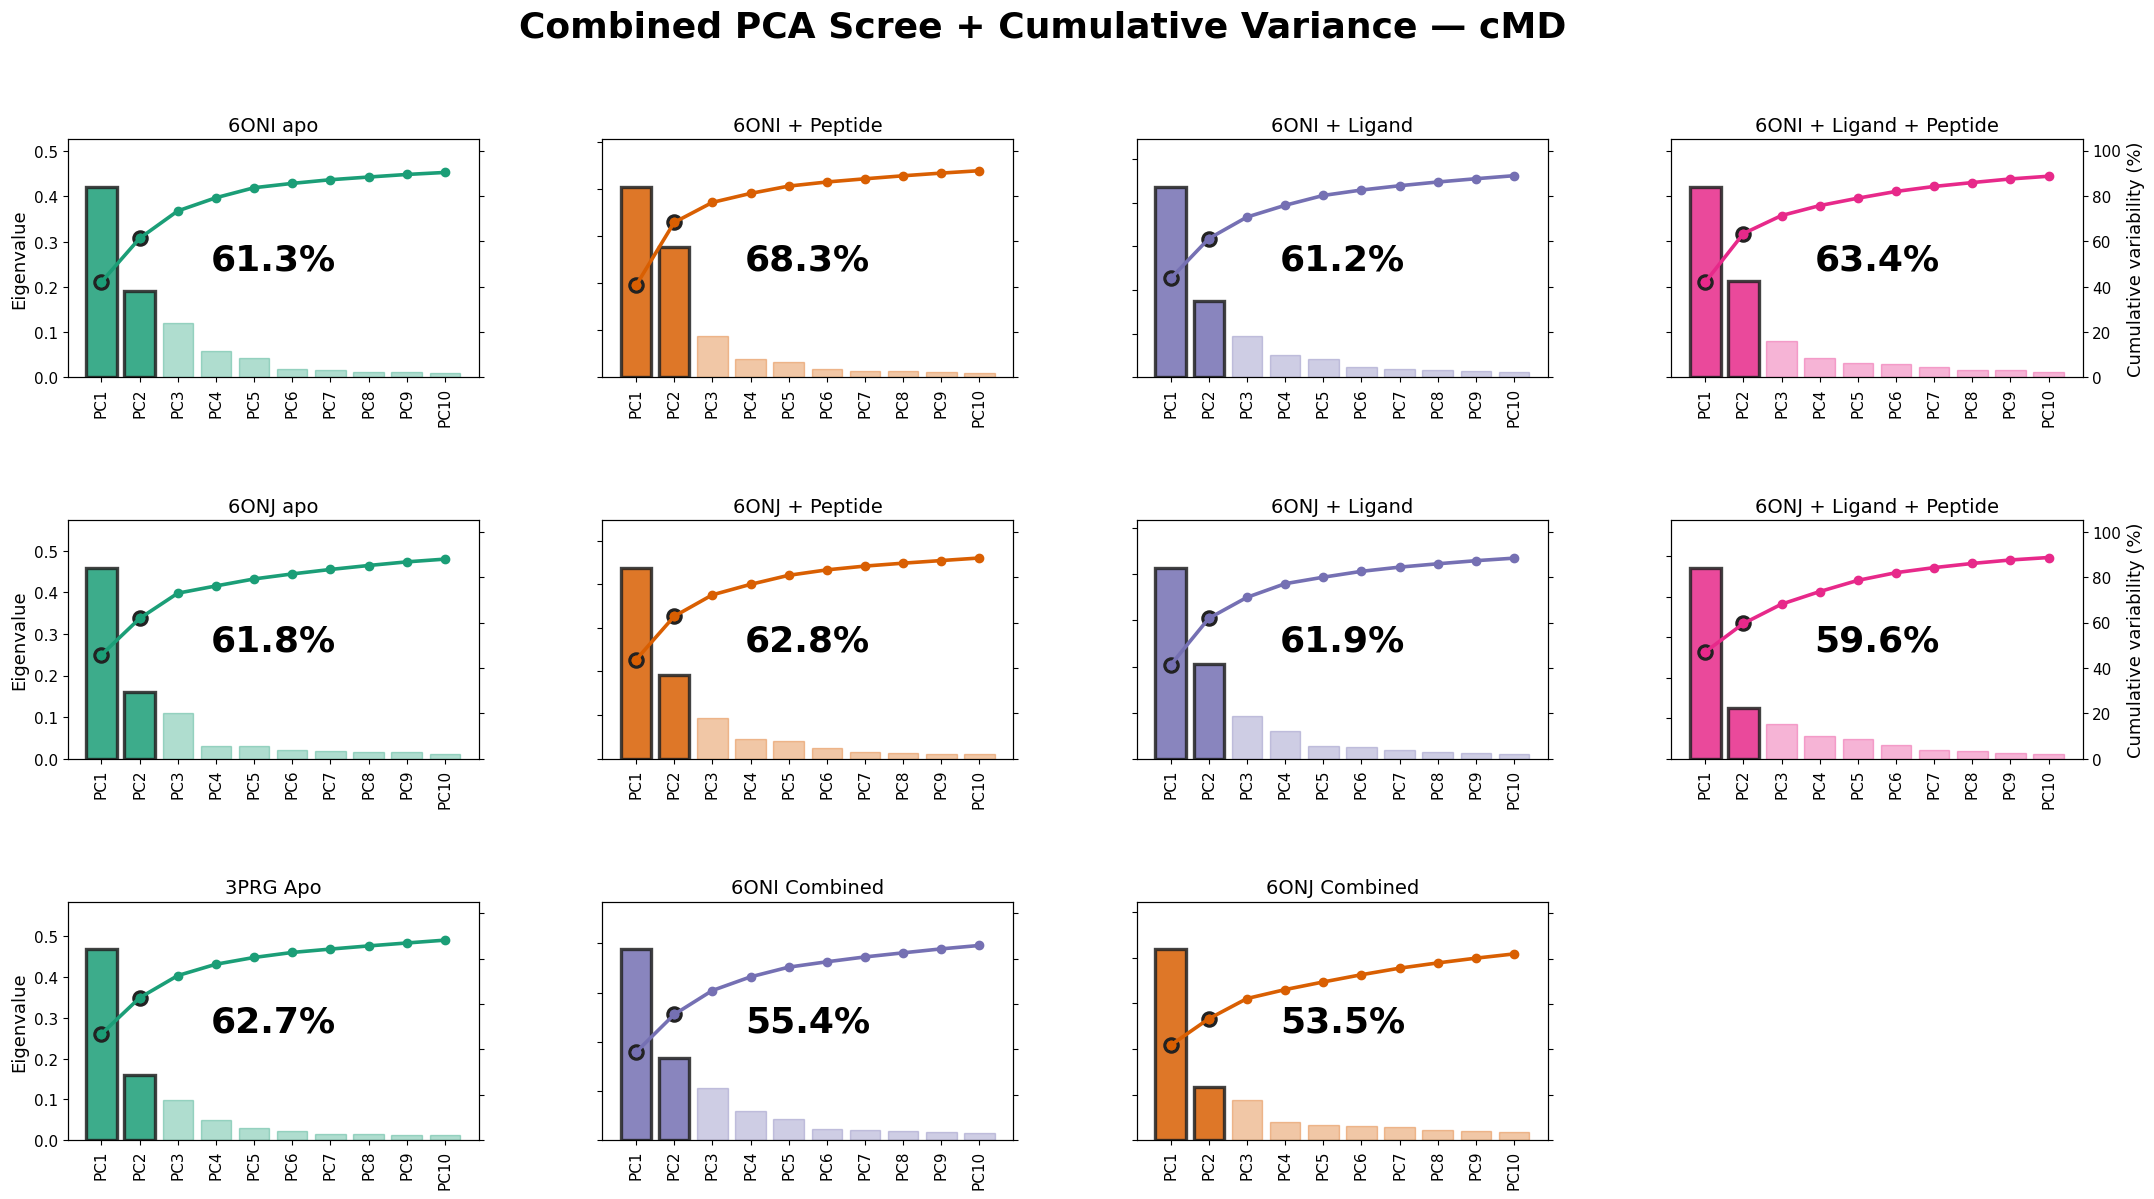

Saved: ./Plots/cMD/AllSystems_combined_PCA_Scree.svg


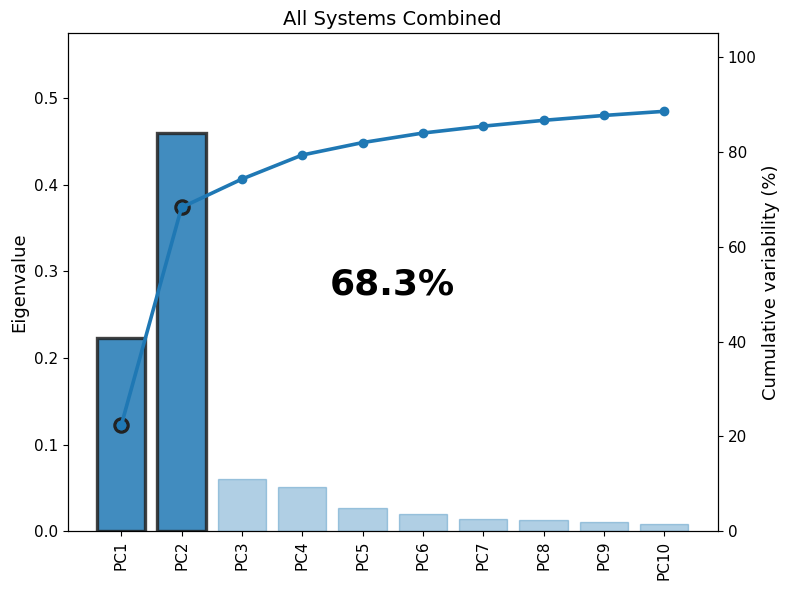

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os, re

BASE = "./cMD"
OUT  = "./Plots/cMD"
os.makedirs(OUT, exist_ok=True)
SAVE_SVG = True

HIGHLIGHT = "#222222"

SUPTITLE_FONT = 26
TITLE_FONT    = 14
LABEL_FONT    = 13
TICK_FONT     = 11
PERCENT_FONT  = 26

row1 = ["6ONI_apo","6ONI_pep_nolig","6ONI_ligand","6ONI_pep_lig"]
row2 = ["6ONJ_apo","6ONJ_pep_nolig","6ONJ_ligand","6ONJ_pep_lig"]
row3 = ["3PRG","6ONI_combined","6ONJ_combined"]

colors = {
    "apo": "#1b9e77",
    "pep_nolig": "#d95f02",
    "ligand": "#7570b3",
    "pep_lig": "#e7298a",
    "3PRG": "#1b9e77",
    "6ONI_combined": "#7570b3",
    "6ONJ_combined": "#d95f02"
}

def pretty(sys):
    if sys=="3PRG": return "3PRG Reference"
    if sys=="6ONI_combined": return "6ONI Combined"
    if sys=="6ONJ_combined": return "6ONJ Combined"
    base = "6ONI" if sys.startswith("6ONI") else "6ONJ"
    if "apo" in sys: cond="apo"
    elif "pep_nolig" in sys: cond="+ Peptide"
    elif "ligand" in sys and "pep" not in sys: cond="+ Ligand"
    elif "pep_lig" in sys: cond="+ Ligand + Peptide"
    return f"{base} {cond}"

def load_evecs(path):
    vals=[]
    with open(path) as fh:
        for l in fh:
            if re.match(r"^\s*\d+\s+[-+0-9.Ee]+", l):
                vals.append(float(l.split()[1]))
    v=np.array(vals)
    return 100*v/v.sum()

def draw(ax, path, title, color, col_idx, ncols=4):
    v = load_evecs(path)
    pcs = np.arange(1,len(v)+1)
    eig = v/100

    bars = ax.bar(pcs[:10], eig[:10], color=color, alpha=0.35, edgecolor=color)
    for i in [0,1]:
        bars[i].set_edgecolor(HIGHLIGHT)
        bars[i].set_linewidth(2.4)
        bars[i].set_alpha(0.85)

    ax.set_ylim(0, max(eig[:10])*1.25)
    ax.tick_params(labelsize=TICK_FONT)

    if col_idx == 0:
        ax.set_ylabel("Eigenvalue", fontsize=LABEL_FONT)
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])

    ax2 = ax.twinx()
    cum = np.cumsum(v)
    ax2.plot(pcs[:10], cum[:10], color=color, lw=2.6, marker="o")
    ax2.scatter(pcs[:2], cum[:2], s=90, facecolors=color,
                edgecolors=HIGHLIGHT, linewidths=2.4)
    ax2.set_ylim(0,105)
    ax2.tick_params(labelsize=TICK_FONT)

    if col_idx == ncols-1:
        ax2.set_ylabel("Cumulative variability (%)", fontsize=LABEL_FONT)
    else:
        ax2.set_ylabel("")
        ax2.set_yticklabels([])

    ax.set_xticks(pcs[:10])
    ax.set_xticklabels([f"PC{i}" for i in pcs[:10]], rotation=90, fontsize=TICK_FONT)

    ax2.text(5.5, 52,
             f"{v[0]+v[1]:.1f}%",
             fontsize=PERCENT_FONT, weight="bold",
             ha="center", va="center")

    ax.set_title(title, fontsize=TITLE_FONT)

# ---------- GRID FIGURE ----------
fig, axes = plt.subplots(3,4, figsize=(26,13))
axes = axes.flatten()

for i,sys in enumerate(row1):
    draw(axes[i], f"{BASE}/{sys}/combined_evecs.dat", pretty(sys),
         colors[sys.replace("6ONI_","")], col_idx=i%4)

for i,sys in enumerate(row2):
    draw(axes[4+i], f"{BASE}/{sys}/combined_evecs.dat", pretty(sys),
         colors[sys.replace("6ONJ_","")], col_idx=(4+i)%4)

draw(axes[8],  f"{BASE}/3PRG/combined_evecs.dat", "3PRG Apo", colors["3PRG"], col_idx=0)
draw(axes[9],  f"{BASE}/6ONI_combined_evecs.dat", "6ONI Combined", colors["6ONI_combined"], col_idx=1)
draw(axes[10], f"{BASE}/6ONJ_combined_evecs.dat", "6ONJ Combined", colors["6ONJ_combined"], col_idx=2)

for ax in axes[11:]:
    ax.axis("off")

fig.suptitle("Combined PCA Scree + Cumulative Variance — cMD",
             fontsize=SUPTITLE_FONT, weight="bold")
plt.subplots_adjust(hspace=0.6, wspace=0.3)

if SAVE_SVG:
    out=f"{OUT}/Combined_reps_PCA_Scree.svg"
    plt.savefig(out,format="svg")
    print("Saved:",out)

plt.show()

# ---------- STANDALONE ALL SYSTEMS ----------
fig2, ax = plt.subplots(figsize=(8,6))
draw(ax, f"{BASE}/cMD_ALL_evecs.dat", "All Systems Combined", "#1f78b4", col_idx=0, ncols=1)
plt.tight_layout()

if SAVE_SVG:
    out=f"{OUT}/AllSystems_combined_PCA_Scree.svg"
    plt.savefig(out,format="svg")
    print("Saved:",out)

plt.show()


## 🌀 Combined PC1–PC2 Projections — cMD (Frame Demarcation)

PC1–PC2 projections from **replicate-combined cMD trajectories** with explicit
**frame demarcation**.

Each individual system is concatenated as sequential blocks of **100,000 frames per replicate**:

- rep1: frames 1–100,000  
- rep2: frames 100,001–200,000  
- rep3: frames 200,001–300,000  

For **combined systems**, trajectories are appended in the following order:

6ONI → 6ONJ → 3PRG

Within each receptor, conditions are ordered as:

apo → pep_nolig → ligand → pep_lig  
(each condition block contains rep1–rep3, 100k frames each)

**Star markers** indicate the first frame of every 100,000-frame block.

**Inputs:**  
`cMD/<system>/combined_pca.dat`, `cMD/6ONI_combined_pca.dat`, `cMD/6ONJ_combined_pca.dat`, `cMD/cMD_ALL_pca.dat`  

**Output (optional):**  
`Plots/cMD/Combined_reps_PCA.svg`, `Plots/cMD/AllSystems_combined_PCA.svg`


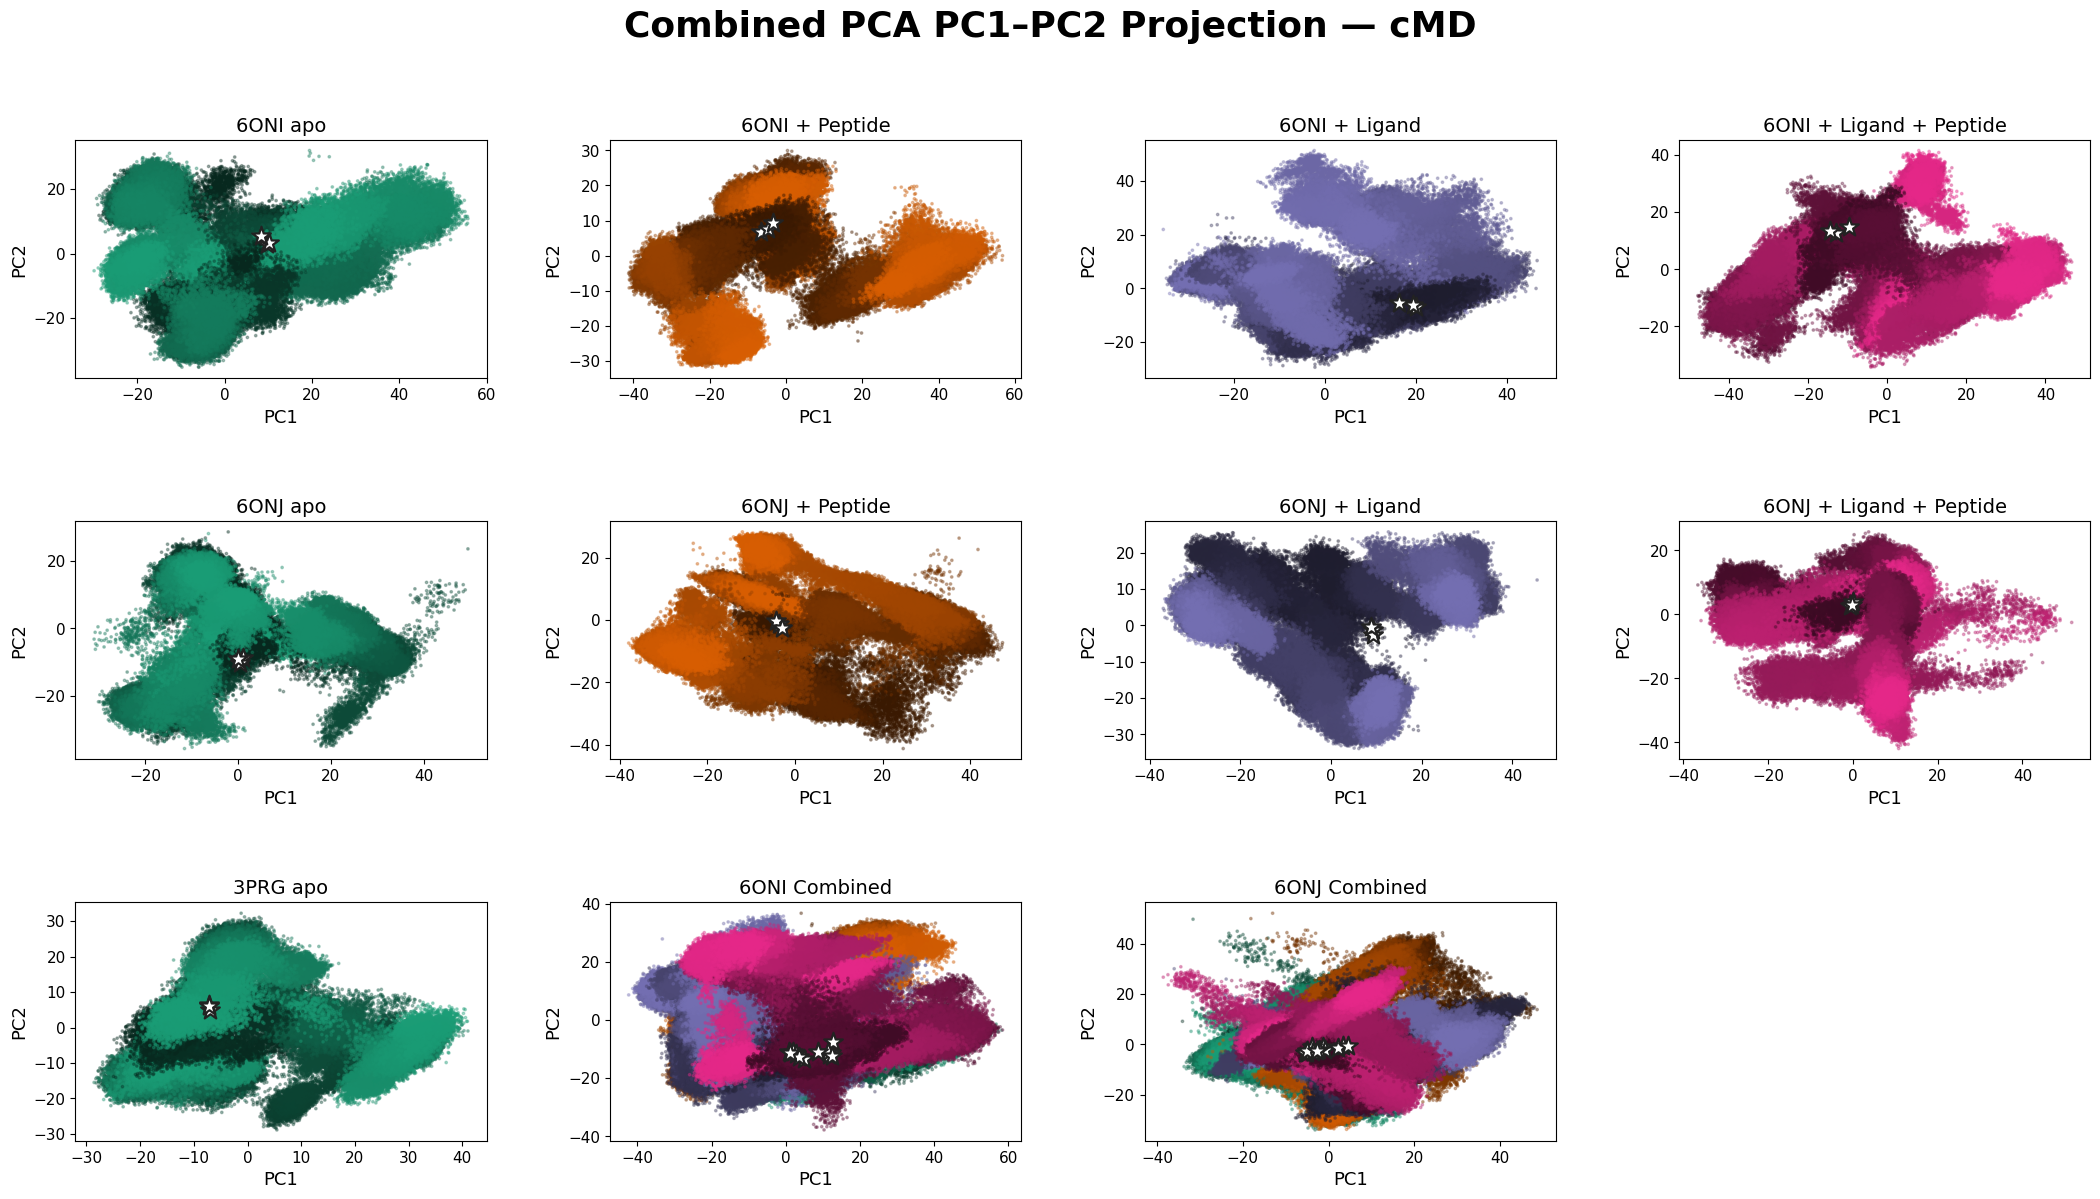

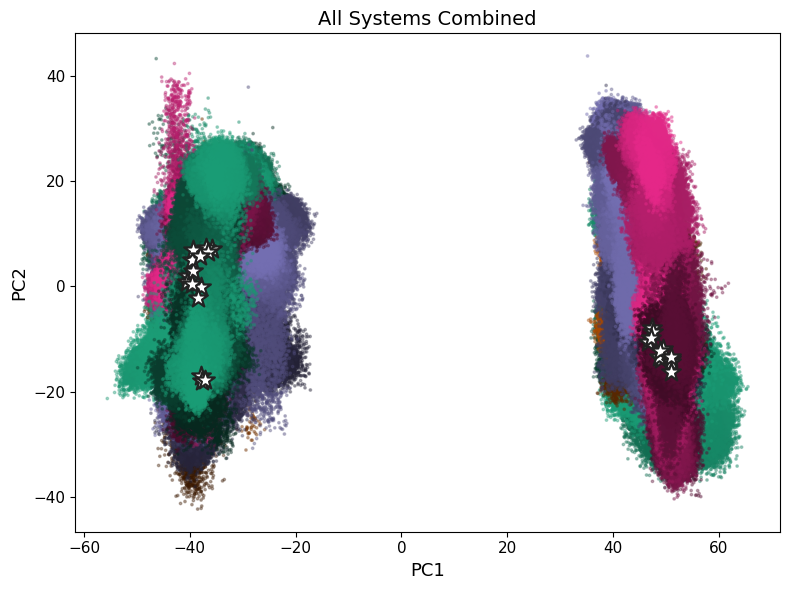

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib.colors import to_rgb

BASE = "./cMD"
OUT  = "./Plots/cMD"
os.makedirs(OUT, exist_ok=True)
SAVE_SVG = False

SUPTITLE_FONT = 26
TITLE_FONT    = 14
LABEL_FONT    = 13
TICK_FONT     = 11
POINT_ALPHA   = 0.35
STAR_SIZE     = 200
REP_SIZE      = 100_000

systems_row1 = ["6ONI_apo","6ONI_pep_nolig","6ONI_ligand","6ONI_pep_lig"]
systems_row2 = ["6ONJ_apo","6ONJ_pep_nolig","6ONJ_ligand","6ONJ_pep_lig"]

colors = {
    "apo": "#1b9e77",
    "pep_nolig": "#d95f02",
    "ligand": "#7570b3",
    "pep_lig": "#e7298a",
    "3PRG": "#1b9e77"
}

def pretty(sys):
    if sys=="3PRG": return "3PRG apo"
    if sys=="6ONI_combined": return "6ONI Combined"
    if sys=="6ONJ_combined": return "6ONJ Combined"
    base = "6ONI" if sys.startswith("6ONI") else "6ONJ"
    if "apo" in sys: cond="apo"
    elif "pep_nolig" in sys: cond="+ Peptide"
    elif "ligand" in sys and "pep" not in sys: cond="+ Ligand"
    elif "pep_lig" in sys: cond="+ Ligand + Peptide"
    return f"{base} {cond}"

def key(sys):
    if sys=="3PRG": return "3PRG"
    return sys.replace("6ONI_","").replace("6ONJ_","")

def load_pca(path):
    d = np.loadtxt(path)
    return d[:,1], d[:,2]

def gradient(color, n):
    r,g,b = to_rgb(color)
    t = np.linspace(0.25, 1.0, REP_SIZE)
    block = np.column_stack([r*t, g*t, b*t])
    return np.vstack([block]*(int(np.ceil(n/REP_SIZE))))[:n]

def combined_colors(order, nframes):
    cols=[]
    for base in order:
        r,g,b = to_rgb(colors[base])
        for _ in range(3):
            t = np.linspace(0.25, 1.0, REP_SIZE)
            cols.append(np.column_stack([r*t, g*t, b*t]))
    return np.vstack(cols)[:nframes]

def star_idx(n):
    return np.arange(0, n, REP_SIZE)

def draw(ax, path, title, color_key, multi=False, order=None):
    pc1, pc2 = load_pca(path)

    if multi:
        cols = combined_colors(order, len(pc1))
    else:
        cols = gradient(colors[color_key], len(pc1))

    ax.scatter(pc1, pc2, s=3, c=cols, alpha=POINT_ALPHA)

    idx = star_idx(len(pc1))
    ax.scatter(pc1[idx], pc2[idx], marker="*", s=STAR_SIZE,
               facecolor="white", edgecolor="#222222",
               linewidth=1.6, zorder=5)

    ax.set_title(title, fontsize=TITLE_FONT)
    ax.set_xlabel("PC1", fontsize=LABEL_FONT)
    ax.set_ylabel("PC2", fontsize=LABEL_FONT)
    ax.tick_params(labelsize=TICK_FONT)

# ---------- GRID ----------
fig, axes = plt.subplots(3,4, figsize=(26,13))
axes = axes.flatten()

for i,sys in enumerate(systems_row1):
    draw(axes[i], f"{BASE}/{sys}/combined_pca.dat",
         pretty(sys), key(sys), multi=False)

for i,sys in enumerate(systems_row2):
    draw(axes[4+i], f"{BASE}/{sys}/combined_pca.dat",
         pretty(sys), key(sys), multi=False)

draw(axes[8], f"{BASE}/3PRG/combined_pca.dat",
     "3PRG apo", "3PRG", multi=False)

draw(axes[9], f"{BASE}/6ONI_combined_pca.dat", "6ONI Combined",
     None, multi=True, order=["apo","pep_nolig","ligand","pep_lig"])

draw(axes[10], f"{BASE}/6ONJ_combined_pca.dat", "6ONJ Combined",
     None, multi=True, order=["apo","pep_nolig","ligand","pep_lig"])

for ax in axes[11:]:
    ax.axis("off")

fig.suptitle("Combined PCA PC1–PC2 Projection — cMD",
             fontsize=SUPTITLE_FONT, weight="bold")
plt.subplots_adjust(hspace=0.6, wspace=0.3)

if SAVE_SVG:
    plt.savefig(f"{OUT}/Combined_reps_PCA.svg", format="svg")

plt.show()

# ---------- ALL SYSTEMS ----------
fig2, ax = plt.subplots(figsize=(8,6))
pc1, pc2 = load_pca(f"{BASE}/cMD_ALL_pca.dat")

cols = combined_colors(
    ["apo","pep_nolig","ligand","pep_lig",
     "apo","pep_nolig","ligand","pep_lig","3PRG"],
    len(pc1)
)

ax.scatter(pc1, pc2, s=3, c=cols, alpha=POINT_ALPHA)

idx = star_idx(len(pc1))
ax.scatter(pc1[idx], pc2[idx], marker="*", s=STAR_SIZE,
           facecolor="white", edgecolor="#222222",
           linewidth=1.6, zorder=5)

ax.set_title("All Systems Combined", fontsize=TITLE_FONT)
ax.set_xlabel("PC1", fontsize=LABEL_FONT)
ax.set_ylabel("PC2", fontsize=LABEL_FONT)
ax.tick_params(labelsize=TICK_FONT)

plt.tight_layout()
if SAVE_SVG:
    plt.savefig(f"{OUT}/AllSystems_combined_PCA.svg", format="svg")

plt.show()


## 🌀 All-Systems PC1–PC2 Projection — cMD (Frame-Demarcated, Orientation Matched to aMD)

PC1 vs PC2 projection from the trajectory concatenated across **all canonical MD systems**.

### Concatenation order

Systems are appended in the following sequence:

6ONI → 6ONJ → 3PRG

Within each receptor, conditions are ordered as:

apo → pep_nolig → ligand → pep_lig  
(each condition contains **rep1–rep3**, 100,000 frames per replicate)

### Frame demarcation

- rep1: frames 1–100,000  
- rep2: frames 100,001–200,000  
- rep3: frames 200,001–300,000  

**Star markers** indicate the first frame of every 100,000-frame block.

### Orientation note

PC1 is reflected solely to **match the orientation used in aMD** so that
**6ONJ lies on the positive side and 6ONI on the negative side**.  
This operation does **not alter the underlying data or variance structure**;
it only removes the arbitrary sign ambiguity of PCA.

**Input:** `cMD/cMD_ALL_pca.dat`  
**Output (optional):** `Plots/cMD/AllSystems_combined_PCA.svg`


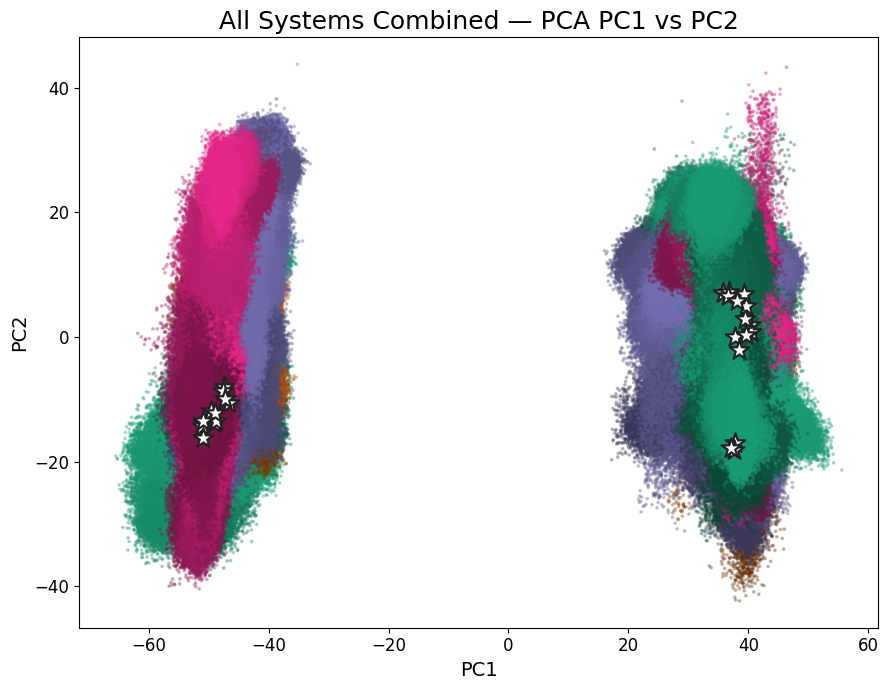

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
import os

BASE = "./cMD"
OUT  = "./Plots/cMD"
os.makedirs(OUT, exist_ok=True)

SAVE_SVG   = False
POINT_ALPHA = 0.28
STAR_SIZE   = 220
REP_SIZE    = 100_000

LABEL_FONT = 14
TICK_FONT  = 12
TITLE_FONT = 18

colors = {
    "apo": "#1b9e77",
    "pep_nolig": "#d95f02",
    "ligand": "#7570b3",
    "pep_lig": "#e7298a",
    "3PRG": "#1b9e77"
}

def load_pca(path):
    d = np.loadtxt(path)
    return d[:,1], d[:,2]

def reflect_pc1(pc1):
    """
    Reflect PC1 if the long-time average lies on the negative side.
    This removes arbitrary PCA sign flips between combined datasets.
    """
    if np.mean(pc1[-REP_SIZE:]) < 0:
        return -pc1
    return pc1

def combined_colors(order, nframes):
    cols=[]
    for base in order:
        r,g,b = to_rgb(colors[base])
        for _ in range(3):
            t = np.linspace(0.45, 1.0, REP_SIZE)
            cols.append(np.column_stack([r*t, g*t, b*t]))
    return np.vstack(cols)[:nframes]

def star_idx(n):
    return np.arange(0, n, REP_SIZE)

# ---------- LOAD DATA ----------
pc1, pc2 = load_pca(f"{BASE}/cMD_ALL_pca.dat")
pc1 = reflect_pc1(pc1)

order = [
    "apo","pep_nolig","ligand","pep_lig",
    "apo","pep_nolig","ligand","pep_lig",
    "3PRG"
]

cols = combined_colors(order, len(pc1))

# ---------- PLOT ----------
fig, ax = plt.subplots(figsize=(9,7))

ax.scatter(pc1, pc2, s=3, c=cols, alpha=POINT_ALPHA)

idx = star_idx(len(pc1))
ax.scatter(pc1[idx], pc2[idx],
           marker="*", s=STAR_SIZE,
           facecolor="white", edgecolor="#222222",
           linewidth=1.6, zorder=5)

ax.set_title("All Systems Combined — PCA PC1 vs PC2", fontsize=TITLE_FONT)
ax.set_xlabel("PC1", fontsize=LABEL_FONT)
ax.set_ylabel("PC2", fontsize=LABEL_FONT)
ax.tick_params(labelsize=TICK_FONT)

plt.tight_layout()

if SAVE_SVG:
    out = f"{OUT}/AllSystems_combined_PCA.svg"
    plt.savefig(out, format="svg")
    print("Saved:", out)

plt.show()


## 🌐 All-Systems PCA KDE Density — cMD

Visualizes the kernel-density estimate (KDE) of the combined PC1–PC2 conformational
space across **all canonical MD systems**.

### Processing steps

- Loads a precomputed KDE grid from:
  `cMD/cMD_ALL_PC1_PC2_KDE_density.csv`
- Mirrors the **PC1 axis** to align the orientation with aMD projections.
- Colors each PC1–PC2 point by its estimated density using the *turbo* colormap.

### Plot details

- Scatter plot of PC1 vs PC2, colored by density value.  
- Color bar reports KDE density.  
- Output is saved as a vector graphic.

**Input:** `cMD/cMD_ALL_PC1_PC2_KDE_density.csv`  
**Output:** `Plots/cMD/AllSystems_PCA_KDE_density.svg`


Saved: ./Plots/cMD/AllSystems_PCA_KDE_density.svg


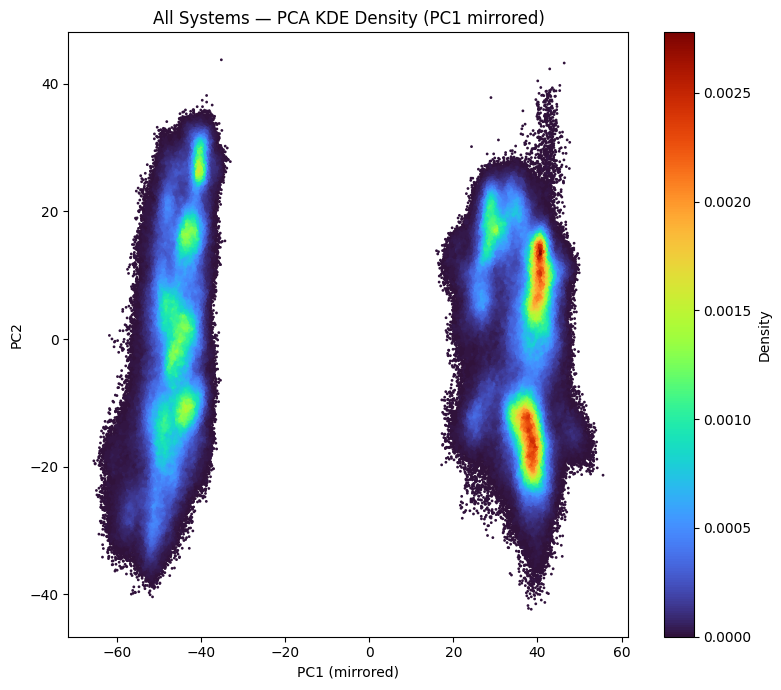

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import os

BASE = "./cMD"
OUT  = "./Plots/cMD"
os.makedirs(OUT, exist_ok=True)

SAVE_SVG = True

KDE_FILE = f"{BASE}/cMD_ALL_PC1_PC2_KDE_density.csv"

kde = np.loadtxt(KDE_FILE, delimiter=",", skiprows=1)
pc1, pc2, dens = kde[:,0], kde[:,1], kde[:,2]

# --------- MIRROR PC1 AXIS ---------
pc1 = -1 * pc1
# ----------------------------------

plt.figure(figsize=(8,7))
sc = plt.scatter(pc1, pc2, c=dens, s=4, cmap="turbo", linewidths=0)

plt.colorbar(sc, label="Density")
plt.xlabel("PC1 (mirrored)")
plt.ylabel("PC2")
plt.title("All Systems — PCA KDE Density (PC1 mirrored)")

plt.tight_layout()

if SAVE_SVG:
    out = f"{OUT}/AllSystems_PCA_KDE_density.svg"
    plt.savefig(out, format="svg")
    print("Saved:", out)

plt.show()


## 🎛️ PCA Condition Panels — cMD (PC1 Mirrored)

Creates condition-separated PC1–PC2 projections from the **cMD all-systems PCA**
trajectory, with a 2×2 condition grid and a fully combined view.

### Processing

- Loads `cMD/cMD_ALL_pca.dat`
- Mirrors **PC1** to match the orientation used for aMD
- Uses global axis limits so all panels are directly comparable

### Top panels (2×2)

Separate projections for each condition:

- **apo**
- **ligand**
- **pep_nolig**
- **pep_lig**

Points are colored with a light→dark time gradient within each block.  
The **3PRG apo** block is highlighted using a steel-blue colormap.

### Bottom panel (combined)

All systems and conditions overlaid:

- Each system block is colored by its condition-specific colormap
- **Star markers** denote the first frame of every **300,000-frame block**
  (3 replicas × 100,000 frames)

### Frame organization

Systems are concatenated in this order:

6ONI_apo → 6ONI_ligand → 6ONI_pep_nolig → 6ONI_pep_lig →  
6ONJ_apo → 6ONJ_ligand → 6ONJ_pep_nolig → 6ONJ_pep_lig → 3PRG_apo

Each block contains **3 replicas × 100,000 frames = 300,000 frames**.

**Input:** `cMD/cMD_ALL_pca.dat`  
**Output (optional):** `Plots/cMD/cMD_PCA_condition_panels.svg`


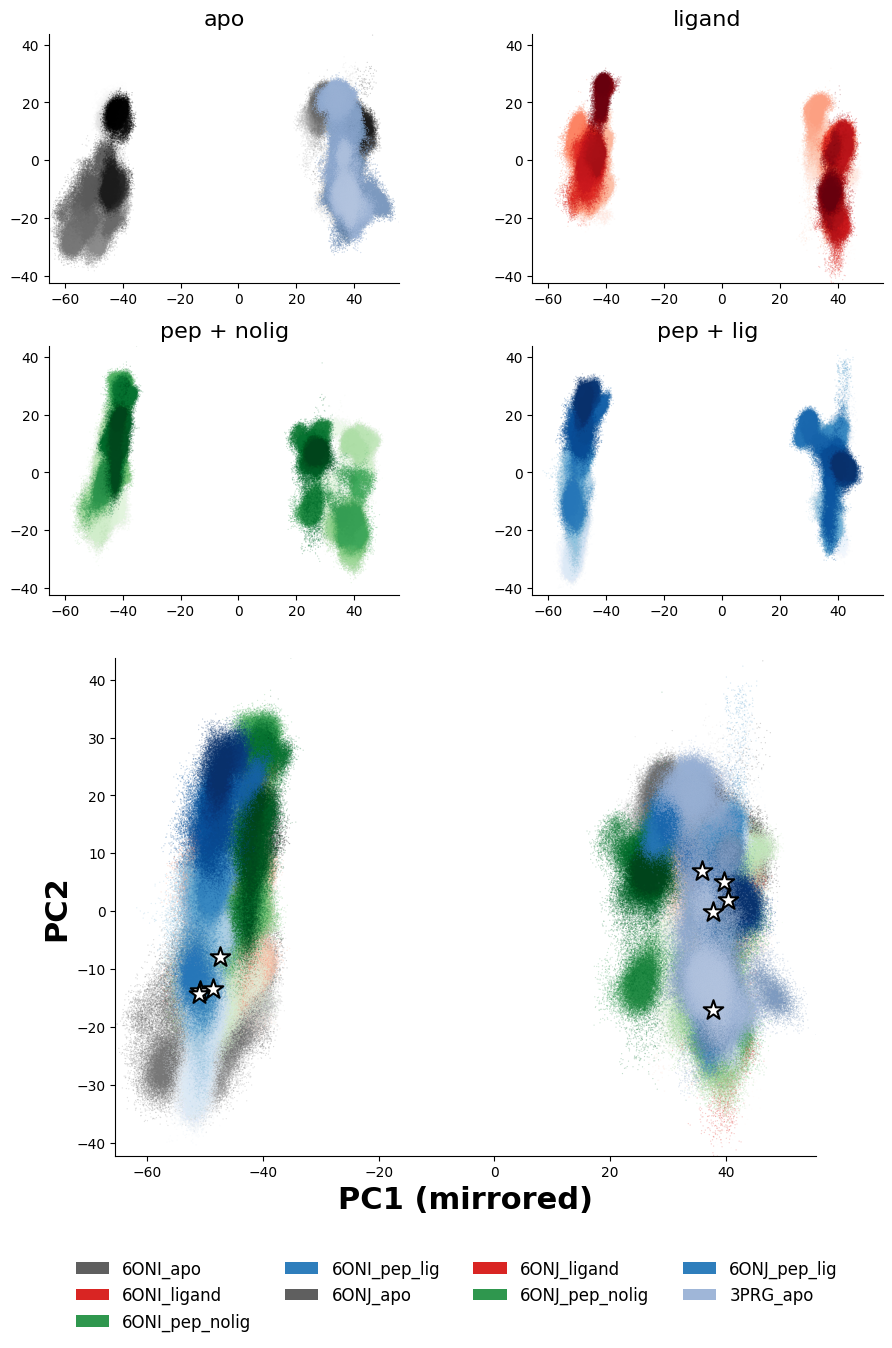

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.colors as mcolors
import os

plt.rcParams['scatter.marker'] = '.'

SAVE_SVG = False     # ⬅️ toggle here to output svg change to True
OUTDIR   = "./Plots/cMD"

PC_LABEL_FONT = 22
TICK_FONT     = 18
TITLE_FONT    = 16
DOT_SIZE      = 4
STAR_SIZE     = 220
ALPHA_POINTS  = 0.25

BASE = "cMD"
PCA_PATH = f"{BASE}/cMD_ALL_pca.dat"

data = np.loadtxt(PCA_PATH)
pc1, pc2 = data[:,1], data[:,2]

# -------- MIRROR PC1 AXIS --------
pc1 = -1 * pc1
# --------------------------------

REP  = 100_000
COND = 3 * REP

system_order = [
    "6ONI_apo","6ONI_ligand","6ONI_pep_nolig","6ONI_pep_lig",
    "6ONJ_apo","6ONJ_ligand","6ONJ_pep_nolig","6ONJ_pep_lig",
    "3PRG_apo"
]

system_cmaps = {
    "apo":       plt.cm.Greys,
    "ligand":    plt.cm.Reds,
    "pep_nolig": plt.cm.Greens,
    "pep_lig":   plt.cm.Blues
}

steelblue_cmap = mcolors.LinearSegmentedColormap.from_list(
    "SteelBlue", ["#5f7fa2", "#8faad1", "#b6c7e2"]
)

block_map = {}
b = 0
for sys in system_order:
    block_map[sys] = [(b*COND,(b+1)*COND)]
    b += 1

condition_sets = {"apo":[], "ligand":[], "pep_nolig":[], "pep_lig":[]}
for sys in system_order:
    for cond in condition_sets:
        if cond in sys:
            condition_sets[cond].extend(block_map[sys])
    if sys == "3PRG_apo":
        condition_sets["apo"].extend(block_map[sys])

xlim = (pc1.min(), pc1.max())
ylim = (pc2.min(), pc2.max())

fig = plt.figure(figsize=(10, 13))
gs = fig.add_gridspec(3, 2, height_ratios=[1,1,2])
axes_top = [fig.add_subplot(gs[i,j]) for i in range(2) for j in range(2)]
cond_order = ["apo","ligand","pep_nolig","pep_lig"]

# -------- TOP PANELS --------
for ax, cond in zip(axes_top, cond_order):
    for (start,end) in condition_sets[cond]:
        idx = np.arange(start,end)
        colors = np.linspace(0.3,0.95,len(idx))
        cmap = steelblue_cmap if cond=="apo" and (start,end) in block_map["3PRG_apo"] else system_cmaps[cond]

        ax.scatter(pc1[idx], pc2[idx], c=colors, cmap=cmap,
                   s=DOT_SIZE*0.8, alpha=ALPHA_POINTS,
                   linewidths=0, rasterized=True)

    ax.set_title(cond.replace("_"," + "), fontsize=TITLE_FONT)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect("equal","box")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# -------- BOTTOM COMBINED --------
ax = fig.add_subplot(gs[2, :])
legend_patches = []

for sys in system_order:
    if sys == "3PRG_apo": cmap = steelblue_cmap
    elif "pep_nolig" in sys: cmap = system_cmaps["pep_nolig"]
    elif "pep_lig" in sys: cmap = system_cmaps["pep_lig"]
    elif "ligand" in sys: cmap = system_cmaps["ligand"]
    else: cmap = system_cmaps["apo"]

    for (start,end) in block_map[sys]:
        idx = np.arange(start,end)
        colors = np.linspace(0.3,0.95,len(idx))
        ax.scatter(pc1[idx], pc2[idx], c=colors, cmap=cmap,
                   s=DOT_SIZE*0.8, alpha=ALPHA_POINTS,
                   linewidths=0, rasterized=True)

    legend_patches.append(Patch(facecolor=cmap(0.7), label=sys))

for i in range(len(system_order)):
    f = i*COND
    ax.scatter(pc1[f], pc2[f], marker="*", s=STAR_SIZE,
               facecolor="white", edgecolor="black",
               linewidth=1.5, zorder=20)

ax.set_xlabel("PC1 (mirrored)", fontsize=PC_LABEL_FONT, fontweight="bold")
ax.set_ylabel("PC2", fontsize=PC_LABEL_FONT, fontweight="bold")
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_aspect("equal","box")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.legend(handles=legend_patches, loc="lower center",
           ncol=4, frameon=False, fontsize=12,
           bbox_to_anchor=(0.5,-0.04))

plt.tight_layout(rect=[0,0.05,1,1])

# -------- SAVE SVG (OFF BY DEFAULT) --------
if SAVE_SVG:
    os.makedirs(OUTDIR, exist_ok=True)
    out = f"{OUTDIR}/cMD_PCA_condition_panels.svg"
    plt.savefig(out, format="svg")
    print("Saved:", out)

plt.show()
